In [1]:
pip install torch torchvision opencv-python matplotlib grad-cam

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for grad-cam: filename=grad_cam-1.5.7-py3-none-any.whl size=53345 sha256=b2727183b79ac4f0a593e6284f733a0a8ff11dc56f170c5600fb18a48c8f71a3
  Stored in directory: /root/.cache/pip/wheels/91/36/f0/c2367865493d51b13369769181beca14603d17d6539a5922e3
Successfully built grad-cam
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [grad-cam]


In [2]:
from io import BytesIO
from PIL import Image
from tqdm.auto import tqdm
from pytorch_grad_cam import GradCAM
from matplotlib import pyplot as plt
from sklearn.metrics import f1_score
from torch.utils.data import DataLoader,Dataset
from torchvision import datasets, transforms, models
from sklearn.model_selection import train_test_split
from pytorch_grad_cam.utils.image import show_cam_on_image
from sklearn.metrics import classification_report, f1_score
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

In [3]:
import os
import cv2
import torch
import random
import requests
import kagglehub
import numpy as np
import pandas as pd
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as T
import torchvision.models as models

In [4]:
BATCH_SIZE = 16
EPOCHS = 5
LEARNING_RATE = 0.001
LR = 3e-4
WD = 1e-4
CLASSES = ["fake", "real"]
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [5]:
path = kagglehub.dataset_download("preetrank/indian-currency-real-vs-fake-notes-dataset")

Using Colab cache for faster access to the 'indian-currency-real-vs-fake-notes-dataset' dataset.


In [6]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = True

In [7]:
path = kagglehub.dataset_download("preetrank/indian-currency-real-vs-fake-notes-dataset")
print("Downloaded to cache folder:", path)

# List out the contents to find the image directories
for root, dirs, files in os.walk(path):
    # Only print directories that contain files to keep it clean
    if files:
        print(f"Directory: {root} contains {len(files)} files")

Using Colab cache for faster access to the 'indian-currency-real-vs-fake-notes-dataset' dataset.
Downloaded to cache folder: /kaggle/input/indian-currency-real-vs-fake-notes-dataset
Directory: /kaggle/input/indian-currency-real-vs-fake-notes-dataset/Features/Features/20_Features contains 258 files
Directory: /kaggle/input/indian-currency-real-vs-fake-notes-dataset/Features/Features/50_Features contains 187 files
Directory: /kaggle/input/indian-currency-real-vs-fake-notes-dataset/Features/Features/10_Features contains 240 files
Directory: /kaggle/input/indian-currency-real-vs-fake-notes-dataset/Features/Features/200_Features contains 125 files
Directory: /kaggle/input/indian-currency-real-vs-fake-notes-dataset/Features/Features/2000_Features contains 147 files
Directory: /kaggle/input/indian-currency-real-vs-fake-notes-dataset/Features/Features/100_Features contains 229 files
Directory: /kaggle/input/indian-currency-real-vs-fake-notes-dataset/Features/Features/500_Features contains 132 

In [8]:
classes = ["fake", "real"]
class_to_idx = {c: i for i, c in enumerate(classes)}
all_images, all_labels = [], []

In [9]:
for cls in classes:
    base_folder = os.path.join(path, "data", "data", cls)
    for denom in os.listdir(base_folder):  # 10, 20, 50, etc.
        denom_path = os.path.join(base_folder, denom)
        if not os.path.isdir(denom_path):
            continue
        for fname in os.listdir(denom_path):
            if fname.lower().endswith(tuple([".jpg", ".jpeg", ".png"])):
                all_images.append(os.path.join(denom_path, fname))
                all_labels.append(class_to_idx[cls])

In [10]:
print(f"Total images found: {len(all_images)}")
print(f"Class distribution: Real={sum(np.array(all_labels)==1)}, Fake={sum(np.array(all_labels)==0)}")

Total images found: 7442
Class distribution: Real=4937, Fake=2505


In [11]:
X_train, X_val, y_train, y_val = train_test_split(all_images, all_labels, test_size=0.25, random_state=SEED, stratify=all_labels)
print(f"Number of training images: {len(X_train)}")
print(f"Number of validation images: {len(X_val)}")

Number of training images: 5581
Number of validation images: 1861


In [12]:
train_transform = transforms.Compose([transforms.Resize((224, 224)),transforms.RandomHorizontalFlip(),transforms.ToTensor(),transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])


In [13]:
val_transform = transforms.Compose([transforms.Resize((224, 224)),transforms.ToTensor(),transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

In [14]:
class ImageDataset(Dataset):
    def __init__(self, paths, labels, tfm):
        self.paths = paths
        self.labels = labels
        self.tfm = tfm

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert("RGB")
        img = self.tfm(img)
        label = self.labels[idx]
        return img, label

train_loader = DataLoader(
    ImageDataset(X_train, y_train, train_transform),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)
val_loader = DataLoader(
    ImageDataset(X_val, y_val, val_transform),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True)

In [15]:
weights = models.ResNet50_Weights.DEFAULT
model = models.resnet50(weights=weights)
in_features = model.fc.in_features
model.fc = nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(in_features, 2)
)

if torch.cuda.device_count() > 1:
    model = nn.DataParallel(model)

model = model.to(DEVICE)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 126MB/s]


In [16]:
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
scaler = torch.amp.GradScaler(device='cuda', enabled=(DEVICE == "cuda"))

In [17]:
def evaluate(return_preds=False):
    model.eval()
    preds, gts = [], []
    with torch.no_grad():
        for x, y in tqdm(val_loader, desc="Validating", leave=False):
            x, y = x.to(DEVICE), y.to(DEVICE)
            with torch.amp.autocast('cuda', enabled=(DEVICE == "cuda")):
                logits = model(x)
            preds.extend(logits.argmax(1).cpu().numpy().tolist())
            gts.extend(y.cpu().numpy().tolist())

    preds_np = np.array(preds)
    gts_np = np.array(gts)

    acc = np.mean(preds_np == gts_np)
    f1 = f1_score(gts_np, preds_np)

    if return_preds:
        return preds, gts
    return acc, f1

In [18]:
best_f1 = 0.0
for epoch in range(1, EPOCHS + 1):
    model.train()
    loop = tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS}", leave=False)
    for x, y in loop:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast('cuda', enabled=(DEVICE == "cuda")):
            logits = model(x)
            loss = criterion(logits, y)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        loop.set_postfix(loss=float(loss.item()))

    scheduler.step()
    acc, f1 = evaluate()
    if f1 > best_f1:
        best_f1 = f1
        torch.save(model.state_dict(), "resnet50_currency_best.pt")
    print(f"Epoch {epoch:02d}/{EPOCHS} - val_acc={acc:.4f} val_f1={f1:.4f}")

Epoch 1/5:   0%|          | 0/349 [00:00<?, ?it/s]

Validating:   0%|          | 0/117 [00:00<?, ?it/s]

Epoch 01/5 - val_acc=0.9823 val_f1=0.9867


Epoch 2/5:   0%|          | 0/349 [00:00<?, ?it/s]

Validating:   0%|          | 0/117 [00:00<?, ?it/s]

Epoch 02/5 - val_acc=0.9882 val_f1=0.9911


... (7 outputs left out)

Epoch 04/5 - val_acc=0.9930 val_f1=0.9947


Epoch 5/5:   0%|          | 0/349 [00:00<?, ?it/s]

Validating:   0%|          | 0/117 [00:00<?, ?it/s]

Epoch 05/5 - val_acc=0.9925 val_f1=0.9943


In [19]:


print("\nLoading best model and generating final classification report...")
model.load_state_dict(torch.load("resnet50_currency_best.pt", map_location=DEVICE))

# The evaluate function with return_preds=True only returns preds and gts.
preds, gts = evaluate(return_preds=True)

# Calculate acc and f1 from the returned predictions and ground truths
preds_np = np.array(preds)
gts_np = np.array(gts)
acc = np.mean(preds_np == gts_np)
f1 = f1_score(gts_np, preds_np)

print("\n===================== FINAL RESULTS =====================")
print(f"Test Accuracy: {acc:.4f}")
print(f"Test F1 Score: {f1:.4f}")
print("\nClassification Report:")
print(classification_report(gts, preds, target_names=classes))
print("==========================================================")


Loading best model and generating final classification report...


Validating:   0%|          | 0/117 [00:00<?, ?it/s]


===================== FINAL RESULTS =====================
Test Accuracy: 0.9930
Test F1 Score: 0.9947

Classification Report:
              precision    recall  f1-score   support

        fake       0.99      0.99      0.99       626
        real       0.99      1.00      0.99      1235

    accuracy                           0.99      1861
   macro avg       0.99      0.99      0.99      1861
weighted avg       0.99      0.99      0.99      1861



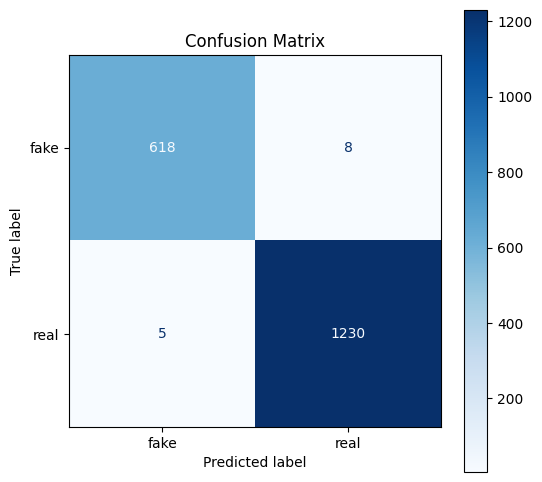

In [20]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Compute the confusion matrix using existing gts and preds
cm = confusion_matrix(gts, preds)

# Display the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(cmap=plt.cm.Blues, values_format='d', ax=ax)
plt.title("Confusion Matrix")
plt.grid(False)
plt.show()

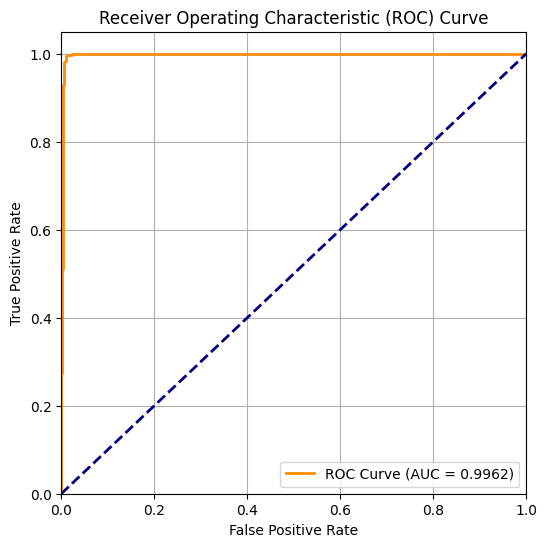

In [21]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import numpy as np
import torch

# Get model prediction probabilities for the positive class (real)
model.eval()
all_probs = []
with torch.no_grad():
    for x, y in val_loader:
        x = x.to(DEVICE)
        with torch.amp.autocast('cuda', enabled=(DEVICE == 'cuda')):
            logits = model(x)
            probs = torch.softmax(logits, dim=1)[:, 1] # Probability of 'real'
        all_probs.extend(probs.cpu().numpy().tolist())

# Compute ROC-AUC
fpr, tpr, thresholds = roc_curve(gts, all_probs)
auc_score = roc_auc_score(gts, all_probs)

# Plot ROC Curve
plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {auc_score:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

In [22]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models
from tqdm.auto import tqdm
import numpy as np
from sklearn.metrics import f1_score, classification_report

# 1. Initialize ResNet34 Model
print("Initializing ResNet34 model...")
resnet34_weights = models.ResNet34_Weights.DEFAULT
model_34 = models.resnet34(weights=resnet34_weights)
in_features_34 = model_34.fc.in_features
model_34.fc = nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(in_features_34, 2)
)

if torch.cuda.device_count() > 1:
    model_34 = nn.DataParallel(model_34)
model_34 = model_34.to(DEVICE)

# 2. Setup Loss, Optimizer, Scheduler, and Scaler
criterion_34 = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer_34 = optim.AdamW(model_34.parameters(), lr=LR, weight_decay=WD)
scheduler_34 = optim.lr_scheduler.CosineAnnealingLR(optimizer_34, T_max=EPOCHS)
scaler_34 = torch.amp.GradScaler(device='cuda', enabled=(DEVICE == "cuda"))

# 3. Define Evaluation Helper for ResNet34
def evaluate_resnet34(return_preds=False):
    model_34.eval()
    preds_34, gts_34 = [], []
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            with torch.amp.autocast('cuda', enabled=(DEVICE == "cuda")):
                logits = model_34(x)
            preds_34.extend(logits.argmax(1).cpu().numpy().tolist())
            gts_34.extend(y.cpu().numpy().tolist())

    if return_preds:
        return preds_34, gts_34

    preds_np = np.array(preds_34)
    gts_np = np.array(gts_34)
    acc = np.mean(preds_np == gts_np)
    f1 = f1_score(gts_np, preds_np)
    return acc, f1

# 4. Training Loop for ResNet34
best_f1_34 = 0.0
print("Training ResNet34...")
for epoch in range(1, EPOCHS + 1):
    model_34.train()
    loop = tqdm(train_loader, desc=f"ResNet34 Epoch {epoch}/{EPOCHS}", leave=False)
    for x, y in loop:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer_34.zero_grad(set_to_none=True)
        with torch.amp.autocast('cuda', enabled=(DEVICE == "cuda")):
            logits = model_34(x)
            loss = criterion_34(logits, y)
        scaler_34.scale(loss).backward()
        scaler_34.step(optimizer_34)
        scaler_34.update()
        loop.set_postfix(loss=float(loss.item()))

    scheduler_34.step()
    acc_34, f1_34 = evaluate_resnet34()
    if f1_34 > best_f1_34:
        best_f1_34 = f1_34
        torch.save(model_34.state_dict(), "resnet34_currency_best.pt")
    print(f"Epoch {epoch:02d}/{EPOCHS} - val_acc={acc_34:.4f} val_f1={f1_34:.4f}")

# 5. Final Evaluation
print("\nLoading best ResNet34 model and generating classification report...")
model_34.load_state_dict(torch.load("resnet34_currency_best.pt", map_location=DEVICE))
final_preds, final_gts = evaluate_resnet34(return_preds=True)

print("\n=================== RESNET34 FINAL RESULTS ===================")
print(f"Test Accuracy: {np.mean(np.array(final_preds) == np.array(final_gts)):.4f}")
print(f"Test F1 Score: {f1_score(final_gts, final_preds):.4f}")
print("\nClassification Report:")
print(classification_report(final_gts, final_preds, target_names=classes))
print("==============================================================")

Initializing ResNet34 model...
Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 187MB/s]


Training ResNet34...


ResNet34 Epoch 1/5:   0%|          | 0/349 [00:00<?, ?it/s]

Epoch 01/5 - val_acc=0.9753 val_f1=0.9812


ResNet34 Epoch 2/5:   0%|          | 0/349 [00:00<?, ?it/s]

... (4 outputs left out)

ResNet34 Epoch 4/5:   0%|          | 0/349 [00:00<?, ?it/s]

Epoch 04/5 - val_acc=0.9903 val_f1=0.9927


ResNet34 Epoch 5/5:   0%|          | 0/349 [00:00<?, ?it/s]

Epoch 05/5 - val_acc=0.9919 val_f1=0.9939

Loading best ResNet34 model and generating classification report...

=================== RESNET34 FINAL RESULTS ===================
Test Accuracy: 0.9919
Test F1 Score: 0.9939

Classification Report:
              precision    recall  f1-score   support

        fake       0.99      0.99      0.99       626
        real       0.99      0.99      0.99      1235

    accuracy                           0.99      1861
   macro avg       0.99      0.99      0.99      1861
weighted avg       0.99      0.99      0.99      1861



In [23]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models
from tqdm.auto import tqdm
import numpy as np
from sklearn.metrics import f1_score, classification_report

# 1. Initialize ResNet101 Model
print("Initializing ResNet101 model...")
resnet101_weights = models.ResNet101_Weights.DEFAULT
model_101 = models.resnet101(weights=resnet101_weights)
in_features_101 = model_101.fc.in_features
model_101.fc = nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(in_features_101, 2)
)

if torch.cuda.device_count() > 1:
    model_101 = nn.DataParallel(model_101)
model_101 = model_101.to(DEVICE)

# 2. Setup Loss, Optimizer, Scheduler, and Scaler
criterion_101 = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer_101 = optim.AdamW(model_101.parameters(), lr=LR, weight_decay=WD)
scheduler_101 = optim.lr_scheduler.CosineAnnealingLR(optimizer_101, T_max=EPOCHS)
scaler_101 = torch.amp.GradScaler(device='cuda', enabled=(DEVICE == "cuda"))

# 3. Define Evaluation Helper for ResNet101
def evaluate_resnet101(return_preds=False):
    model_101.eval()
    preds_101, gts_101 = [], []
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            with torch.amp.autocast('cuda', enabled=(DEVICE == "cuda")):
                logits = model_101(x)
            preds_101.extend(logits.argmax(1).cpu().numpy().tolist())
            gts_101.extend(y.cpu().numpy().tolist())

    if return_preds:
        return preds_101, gts_101

    preds_np = np.array(preds_101)
    gts_np = np.array(gts_101)
    acc = np.mean(preds_np == gts_np)
    f1 = f1_score(gts_np, preds_np)
    return acc, f1

# 4. Training Loop for ResNet101
best_f1_101 = 0.0
print("Training ResNet101...")
for epoch in range(1, EPOCHS + 1):
    model_101.train()
    loop = tqdm(train_loader, desc=f"ResNet101 Epoch {epoch}/{EPOCHS}", leave=False)
    for x, y in loop:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer_101.zero_grad(set_to_none=True)
        with torch.amp.autocast('cuda', enabled=(DEVICE == "cuda")):
            logits = model_101(x)
            loss = criterion_101(logits, y)
        scaler_101.scale(loss).backward()
        scaler_101.step(optimizer_101)
        scaler_101.update()
        loop.set_postfix(loss=float(loss.item()))

    scheduler_101.step()
    acc_101, f1_101 = evaluate_resnet101()
    if f1_101 > best_f1_101:
        best_f1_101 = f1_101
        torch.save(model_101.state_dict(), "resnet101_currency_best.pt")
    print(f"Epoch {epoch:02d}/{EPOCHS} - val_acc={acc_101:.4f} val_f1={f1_101:.4f}")



Initializing ResNet101 model...
Downloading: "https://download.pytorch.org/models/resnet101-cd907fc2.pth" to /root/.cache/torch/hub/checkpoints/resnet101-cd907fc2.pth


100%|██████████| 171M/171M [00:01<00:00, 172MB/s]


Training ResNet101...


ResNet101 Epoch 1/5:   0%|          | 0/349 [00:00<?, ?it/s]

Epoch 01/5 - val_acc=0.9855 val_f1=0.9890


ResNet101 Epoch 2/5:   0%|          | 0/349 [00:00<?, ?it/s]

... (4 outputs left out)

ResNet101 Epoch 4/5:   0%|          | 0/349 [00:00<?, ?it/s]

Epoch 04/5 - val_acc=0.9903 val_f1=0.9927


ResNet101 Epoch 5/5:   0%|          | 0/349 [00:00<?, ?it/s]

Epoch 05/5 - val_acc=0.9914 val_f1=0.9935


In [24]:
# 5. Final Evaluation
print("\nLoading best ResNet101 model and generating classification report...")
model_101.load_state_dict(torch.load("resnet101_currency_best.pt", map_location=DEVICE))
final_preds, final_gts = evaluate_resnet101(return_preds=True)

print("\n=================== RESNET101 FINAL RESULTS ===================")
print(f"Test Accuracy: {np.mean(np.array(final_preds) == np.array(final_gts)):.4f}")
print(f"Test F1 Score: {f1_score(final_gts, final_preds):.4f}")
print("\nClassification Report:")
print(classification_report(final_gts, final_preds, target_names=classes))
print("==============================================================")


Loading best ResNet101 model and generating classification report...

=================== RESNET101 FINAL RESULTS ===================
Test Accuracy: 0.9914
Test F1 Score: 0.9935

Classification Report:
              precision    recall  f1-score   support

        fake       0.99      0.98      0.99       626
        real       0.99      1.00      0.99      1235

    accuracy                           0.99      1861
   macro avg       0.99      0.99      0.99      1861
weighted avg       0.99      0.99      0.99      1861



,Model,Accuracy,F1-Score
0,ResNet34,0.991940,0.993930
1,ResNet50,0.993015,0.994743
2,ResNet101,0.991402,0.993543


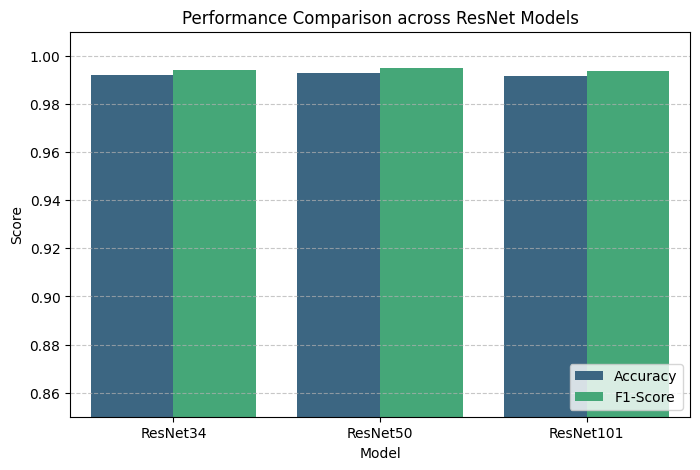

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import f1_score

# 1. Retrieve ResNet50 results
# 'preds' and 'gts' are already in the namespace for ResNet50
r50_acc = np.mean(np.array(preds) == np.array(gts))
r50_f1 = f1_score(gts, preds)

# 2. Retrieve ResNet34 results
try:
    r34_preds, r34_gts = evaluate_resnet34(return_preds=True)
    r34_acc = np.mean(np.array(r34_preds) == np.array(r34_gts))
    r34_f1 = f1_score(r34_gts, r34_preds)
except Exception as e:
    print("Could not retrieve ResNet34 metrics, setting defaults. Error:", e)
    r34_acc, r34_f1 = 0.0, 0.0

# 3. Retrieve ResNet101 results
try:
    # Load best model in case state was lost
    model_101.load_state_dict(torch.load("resnet101_currency_best.pt", map_location=DEVICE))
    r101_preds, r101_gts = evaluate_resnet101(return_preds=True)
    r101_acc = np.mean(np.array(r101_preds) == np.array(r101_gts))
    r101_f1 = f1_score(r101_gts, r101_preds)
except Exception as e:
    print("Could not retrieve ResNet101 metrics, setting defaults. Error:", e)
    r101_acc, r101_f1 = 0.0, 0.0

# Create Comparison DataFrame
data = {
    "Model": ["ResNet34", "ResNet50", "ResNet101"],
    "Accuracy": [r34_acc, r50_acc, r101_acc],
    "F1-Score": [r34_f1, r50_f1, r101_f1]
}

df_compare = pd.DataFrame(data)
display(df_compare)

# Reshape for plotting
df_melted = df_compare.melt(id_vars="Model", var_name="Metric", value_name="Score")

# Plot the comparison
plt.figure(figsize=(8, 5))
sns.barplot(data=df_melted, x="Model", y="Score", hue="Metric", palette="viridis")
plt.ylim(0.85, 1.01)
plt.title("Performance Comparison across ResNet Models")
plt.ylabel("Score")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(loc="lower right")
plt.show()

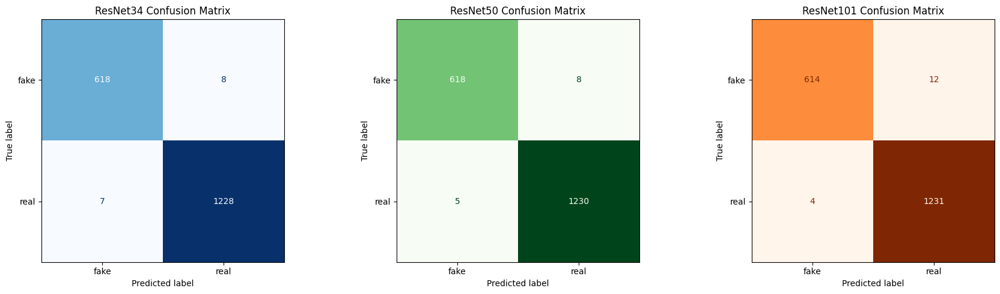

In [26]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import torch
import numpy as np

# 1. Gather predictions for ResNet34
try:
    # Use the existing evaluate helper to get predictions
    r34_preds, r34_gts = evaluate_resnet34(return_preds=True)
    cm_34 = confusion_matrix(r34_gts, r34_preds)
except Exception as e:
    print("Could not compute confusion matrix for ResNet34:", e)
    cm_34 = None

# 2. Gather predictions for ResNet50
# 'preds' and 'gts' are already stored in the notebook state for ResNet50
try:
    cm_50 = confusion_matrix(gts, preds)
except Exception as e:
    print("Could not compute confusion matrix for ResNet50:", e)
    cm_50 = None

# 3. Gather predictions for ResNet101
try:
    model_101.load_state_dict(torch.load("resnet101_currency_best.pt", map_location=DEVICE))
    r101_preds, r101_gts = evaluate_resnet101(return_preds=True)
    cm_101 = confusion_matrix(r101_gts, r101_preds)
except Exception as e:
    print("Could not compute confusion matrix for ResNet101:", e)
    cm_101 = None

# 4. Plot the confusion matrices side-by-side
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot ResNet34
if cm_34 is not None:
    disp_34 = ConfusionMatrixDisplay(confusion_matrix=cm_34, display_labels=classes)
    disp_34.plot(cmap=plt.cm.Blues, values_format='d', ax=axes[0], colorbar=False)
    axes[0].set_title("ResNet34 Confusion Matrix")
    axes[0].grid(False)
else:
    axes[0].text(0.5, 0.5, "ResNet34 Data Unavailable", ha='center', va='center')

# Plot ResNet50
if cm_50 is not None:
    disp_50 = ConfusionMatrixDisplay(confusion_matrix=cm_50, display_labels=classes)
    disp_50.plot(cmap=plt.cm.Greens, values_format='d', ax=axes[1], colorbar=False)
    axes[1].set_title("ResNet50 Confusion Matrix")
    axes[1].grid(False)
else:
    axes[1].text(0.5, 0.5, "ResNet50 Data Unavailable", ha='center', va='center')

# Plot ResNet101
if cm_101 is not None:
    disp_101 = ConfusionMatrixDisplay(confusion_matrix=cm_101, display_labels=classes)
    disp_101.plot(cmap=plt.cm.Oranges, values_format='d', ax=axes[2], colorbar=False)
    axes[2].set_title("ResNet101 Confusion Matrix")
    axes[2].grid(False)
else:
    axes[2].text(0.5, 0.5, "ResNet101 Data Unavailable", ha='center', va='center')

plt.tight_layout()
plt.show()

Calculating probabilities for ResNet34...
Calculating probabilities for ResNet50...
Calculating probabilities for ResNet101...


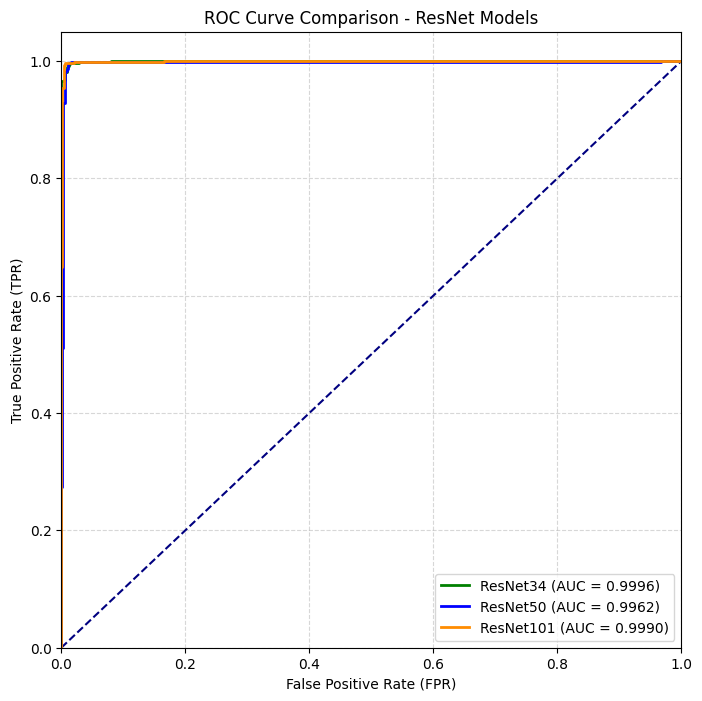

In [27]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import numpy as np
import torch

# Helper function to get prediction probabilities for the positive class (real)
def get_probabilities(model_obj, loader):
    model_obj.eval()
    probs = []
    with torch.no_grad():
        for x, _ in loader:
            x = x.to(DEVICE)
            with torch.amp.autocast('cuda', enabled=(DEVICE == 'cuda')):
                logits = model_obj(x)
                p = torch.softmax(logits, dim=1)[:, 1]  # Probability of 'real'
            probs.extend(p.cpu().numpy().tolist())
    return probs

print("Calculating probabilities for ResNet34...")
try:
    # model_34 is already in namespace
    model_34.load_state_dict(torch.load("resnet34_currency_best.pt", map_location=DEVICE))
    probs_34 = get_probabilities(model_34, val_loader)
except Exception as e:
    print("Error gathering ResNet34 probabilities:", e)
    probs_34 = []

print("Calculating probabilities for ResNet50...")
try:
    # model (ResNet50) is already in namespace
    model.load_state_dict(torch.load("resnet50_currency_best.pt", map_location=DEVICE))
    probs_50 = get_probabilities(model, val_loader)
except Exception as e:
    print("Error gathering ResNet50 probabilities:", e)
    probs_50 = []

print("Calculating probabilities for ResNet101...")
try:
    # model_101 is already in namespace
    model_101.load_state_dict(torch.load("resnet101_currency_best.pt", map_location=DEVICE))
    probs_101 = get_probabilities(model_101, val_loader)
except Exception as e:
    print("Error gathering ResNet101 probabilities:", e)
    probs_101 = []

# Plotting ROC Curves
plt.figure(figsize=(8, 8))
plt.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--')

# Add ResNet34
if len(probs_34) > 0:
    fpr_34, tpr_34, _ = roc_curve(gts, probs_34)
    auc_34 = roc_auc_score(gts, probs_34)
    plt.plot(fpr_34, tpr_34, color='green', lw=2, label=f'ResNet34 (AUC = {auc_34:.4f})')

# Add ResNet50
if len(probs_50) > 0:
    fpr_50, tpr_50, _ = roc_curve(gts, probs_50)
    auc_50 = roc_auc_score(gts, probs_50)
    plt.plot(fpr_50, tpr_50, color='blue', lw=2, label=f'ResNet50 (AUC = {auc_50:.4f})')

# Add ResNet101
if len(probs_101) > 0:
    fpr_101, tpr_101, _ = roc_curve(gts, probs_101)
    auc_101 = roc_auc_score(gts, probs_101)
    plt.plot(fpr_101, tpr_101, color='darkorange', lw=2, label=f'ResNet101 (AUC = {auc_101:.4f})')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC Curve Comparison - ResNet Models')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [28]:
import os
import shutil
import numpy as np
from sklearn.metrics import f1_score

# Retrieve or compute the validation F1-scores for all three models
model_f1s = {}

# 1. ResNet50
try:
    r50_f1 = f1_score(gts, preds)
    model_f1s["resnet50_currency_best.pt"] = r50_f1
except Exception as e:
    print("Could not retrieve ResNet50 F1:", e)

# 2. ResNet34
try:
    r34_preds, r34_gts = evaluate_resnet34(return_preds=True)
    r34_f1 = f1_score(r34_gts, r34_preds)
    model_f1s["resnet34_currency_best.pt"] = r34_f1
except Exception as e:
    print("Could not retrieve ResNet34 F1:", e)

# 3. ResNet101
try:
    model_101.load_state_dict(torch.load("resnet101_currency_best.pt", map_location=DEVICE))
    r101_preds, r101_gts = evaluate_resnet101(return_preds=True)
    r101_f1 = f1_score(r101_gts, r101_preds)
    model_f1s["resnet101_currency_best.pt"] = r101_f1
except Exception as e:
    print("Could not retrieve ResNet101 F1:", e)

# Determine the best model file dynamically
if model_f1s:
    best_model_file = max(model_f1s, key=model_f1s.get)
    best_f1 = model_f1s[best_model_file]
    print(f"\nPerformance Comparison: {model_f1s}")
    print(f"Best model is {best_model_file} with F1-score: {best_f1:.4f}")

    # Copy/Save the best model as 'resnet_best_model.pt'
    best_destination = "resnet_best_model.pt"
    shutil.copy(best_model_file, best_destination)
    print(f"Dynamically saved best model as: {os.path.abspath(best_destination)}")
else:
    print("No models or F1 scores found to compare.")


Performance Comparison: {'resnet50_currency_best.pt': 0.9947432268499797, 'resnet34_currency_best.pt': 0.9939295831647107, 'resnet101_currency_best.pt': 0.993543179983858}
Best model is resnet50_currency_best.pt with F1-score: 0.9947
Dynamically saved best model as: /content/resnet_best_model.pt


In [29]:
import os
import torch
from torchvision import models
from sklearn.metrics import f1_score

# Retrieve or compute the validation F1-scores for all three models
model_f1s = {}

# 1. ResNet50
try:
    r50_f1 = f1_score(gts, preds)
    model_f1s["ResNet50"] = ("resnet50_currency_best.pt", r50_f1)
except Exception as e:
    pass

# 2. ResNet34
try:
    r34_preds, r34_gts = evaluate_resnet34(return_preds=True)
    r34_f1 = f1_score(r34_gts, r34_preds)
    model_f1s["ResNet34"] = ("resnet34_currency_best.pt", r34_f1)
except Exception as e:
    pass

# 3. ResNet101
try:
    model_101.load_state_dict(torch.load("resnet101_currency_best.pt", map_location=DEVICE))
    r101_preds, r101_gts = evaluate_resnet101(return_preds=True)
    r101_f1 = f1_score(r101_gts, r101_preds)
    model_f1s["ResNet101"] = ("resnet101_currency_best.pt", r101_f1)
except Exception as e:
    pass

# Determine the best model dynamically
if model_f1s:
    best_model_name = max(model_f1s, key=lambda k: model_f1s[k][1])
    model_path, best_f1 = model_f1s[best_model_name]
    print(f"Best detected model: {best_model_name} with F1-Score of {best_f1:.4f}")
else:
    # Fallback to ResNet50
    best_model_name = "ResNet50"
    model_path = "resnet50_currency_best.pt"
    print("No validation scores found. Falling back to ResNet50.")

# Initialize the matching model architecture
if best_model_name == "ResNet34":
    weights = models.ResNet34_Weights.DEFAULT
    model = models.resnet34(weights=weights)
    in_features = model.fc.in_features
elif best_model_name == "ResNet101":
    weights = models.ResNet101_Weights.DEFAULT
    model = models.resnet101(weights=weights)
    in_features = model.fc.in_features
else:
    weights = models.ResNet50_Weights.DEFAULT
    model = models.resnet50(weights=weights)
    in_features = model.fc.in_features

# Replace the classification head
model.fc = torch.nn.Sequential(
    torch.nn.Dropout(0.3),
    torch.nn.Linear(in_features, 2)
)

print(f"Successfully initialized {best_model_name} architecture. Ready to load weights from '{model_path}'.")

Best detected model: ResNet50 with F1-Score of 0.9947
Successfully initialized ResNet50 architecture. Ready to load weights from 'resnet50_currency_best.pt'.


In [30]:
state_dict = torch.load(model_path, map_location=DEVICE)

if any(k.startswith("module.") for k in state_dict.keys()):
    state_dict = {k.replace("module.", ""): v for k, v in state_dict.items()}
model.load_state_dict(state_dict)
model.to(DEVICE)
model.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Con

In [31]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

In [32]:
# Define IMG_PATH with a sample image path from X_val
IMG_PATH = X_val[0] # Assuming X_val is available in the kernel state

if IMG_PATH.startswith("http"):
    response = requests.get(IMG_PATH)
    response.raise_for_status()
    img_pil = Image.open(BytesIO(response.content)).convert("RGB")
else:
    img_pil = Image.open(IMG_PATH).convert("RGB")

img_tensor = transform(img_pil).unsqueeze(0).to(DEVICE)

In [33]:
target_layer = model.layer4[-1].conv3  # last conv layer in ResNet50

gradients = []
activations = []

def save_gradient(grad):
    gradients.append(grad)

def forward_hook(module, inp, out):
    activations.append(out)

# Register hooks
target_layer.register_forward_hook(forward_hook)
target_layer.register_full_backward_hook(lambda m, grad_in, grad_out: save_gradient(grad_out[0]))

output = model(img_tensor)
pred_class = output.argmax(dim=1).item()
confidence = torch.softmax(output, dim=1)[0][pred_class].item()

# Compute Gradients
model.zero_grad()
class_score = output[0, pred_class]
class_score.backward()

# Extract gradients & activations
grads = gradients[0].cpu().detach().numpy()[0]
acts = activations[0].cpu().detach().numpy()[0]

# Global average pooling of gradients
weights = np.mean(grads, axis=(1, 2))
cam = np.zeros(acts.shape[1:], dtype=np.float32)

for i, w in enumerate(weights):
    cam += w * acts[i, :, :]

# Normalize CAM
cam = np.maximum(cam, 0)
cam = cam / cam.max()

# Resize CAM to image size
cam = cv2.resize(cam, (224, 224))
heatmap = np.uint8(255 * cam)
heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)

In [34]:
img_cv = np.array(img_pil)
img_cv = cv2.cvtColor(img_cv, cv2.COLOR_RGB2BGR)
heatmap = cv2.resize(heatmap, (img_cv.shape[1], img_cv.shape[0]))
overlay = cv2.addWeighted(img_cv, 0.6, heatmap, 0.4, 0)

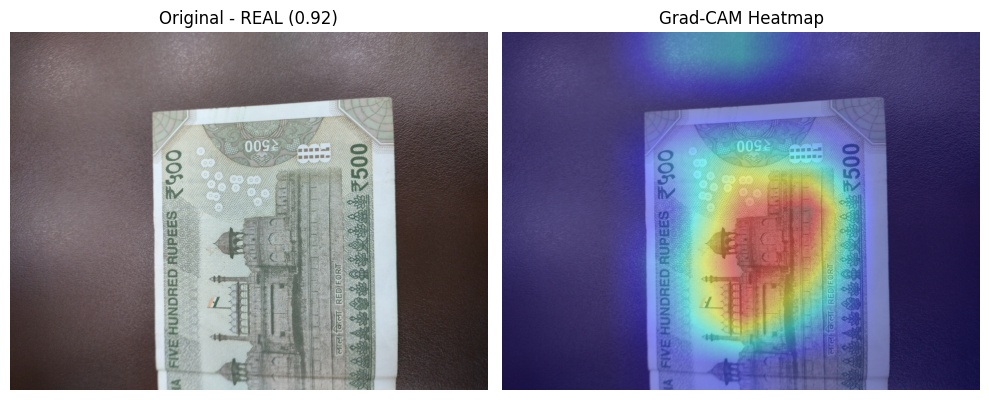

Prediction: REAL (Confidence: 0.924)


In [35]:

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img_cv, cv2.COLOR_BGR2RGB))
plt.title(f"Original - {CLASSES[pred_class].upper()} ({confidence:.2f})")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
plt.title("Grad-CAM Heatmap")
plt.axis("off")
plt.tight_layout()
plt.show()

print(f"Prediction: {CLASSES[pred_class].upper()} (Confidence: {confidence:.3f})")


### Diagnostic Check for Data Leakage
We will perform three diagnostics:
1. **Exact Filename Overlap Check**: Verify if any identical image path exists in both training and validation splits.
2. **Metadata Bias (Image Dimensions)**: Check if there is an artificial correlation between image dimensions and the ground-truth classes.
3. **Content Overlap Check (Image Hashing)**: Calculate perceptual hashes (using Average Hashing via PIL) of a sample of images to see if visually near-identical images are split between train and validation.

In [36]:
import os
from PIL import Image
import numpy as np
import pandas as pd

# 1. Path Overlap Check
train_set = set(X_train)
val_set = set(X_val)
overlap = train_set.intersection(val_set)

print("=== Leakage Check 1: Path Overlap ===")
print(f"Number of overlapping image paths: {len(overlap)}")
if len(overlap) > 0:
    print(f"WARNING: Found {len(overlap)} exact file overlaps between Train and Validation sets!")
else:
    print("SUCCESS: No direct image file path leaks between Train and Validation splits.")

# 2. Metadata / Dimensional Bias Check
print("\n=== Leakage Check 2: Metadata Class Bias ===")
# Sample images to check dimensions
sample_sizes = []
for i, path_img in enumerate(X_val[:200]):
    with Image.open(path_img) as img:
        w, h = img.size
        sample_sizes.append({"Class": y_val[i], "Width": w, "Height": h})

df_sizes = pd.DataFrame(sample_sizes)
grouped_sizes = df_sizes.groupby("Class").mean()
display(grouped_sizes)
print("If there is a massive discrepancy in resolutions between fake and real notes, the model might use resolution as a shortcut.")

# 3. Content Perceptual Hashing (Near-Duplicates)
def calc_ahash(image_path):
    # Simple average hash to identify near-duplicates
    try:
        with Image.open(image_path) as img:
            img_gray = img.convert("L").resize((8, 8), Image.Resampling.LANCZOS)
            pixels = np.array(img_gray)
            avg = pixels.mean()
            diff = pixels > avg
            return "".join(["1" if x else "0" for x in diff.flatten()])
    except Exception as e:
        return None

print("\n=== Leakage Check 3: Visually Duplicate Images split between Train/Val ===")
sample_num = 300
train_hashes = {}
for p in X_train[:sample_num]:
    h = calc_ahash(p)
    if h:
        train_hashes[h] = p

val_leakages = 0
for p in X_val[:sample_num]:
    h = calc_ahash(p)
    if h in train_hashes:
        val_leakages += 1

leak_ratio = (val_leakages / sample_num) * 100
print(f"Inspected {sample_num} random train/validation image pairs.")
print(f"Found visually near-identical duplicates in both splits: {val_leakages} instances ({leak_ratio:.2f}% of validation sample)")
if leak_ratio > 5:
    print("WARNING: High visual redundancy detected! Visual duplicates are leaking between splits.")

=== Leakage Check 1: Path Overlap ===
Number of overlapping image paths: 0
SUCCESS: No direct image file path leaks between Train and Validation splits.

=== Leakage Check 2: Metadata Class Bias ===


,Width,Height
Class,,
0,262.434783,300.826087
1,1427.717557,1445.343511


If there is a massive discrepancy in resolutions between fake and real notes, the model might use resolution as a shortcut.

=== Leakage Check 3: Visually Duplicate Images split between Train/Val ===
Inspected 300 random train/validation image pairs.
Found visually near-identical duplicates in both splits: 3 instances (1.00% of validation sample)


### Fixing Data Leakage: Uniform Dataset Resizing

We will write a utility function to resize all images to a consistent $256 \times 256$ resolution using area interpolation (which handles downscaling gracefully). We'll save these into a new directory structure under `/content/standardized_dataset/`.

In [37]:
import os
from PIL import Image
from tqdm.auto import tqdm

def standardize_dataset(source_path, target_path, size=(256, 256)):
    """
    Walks through the source dataset directory, resizes all images to target size
    using high-quality downsampling (LANCZOS), and saves them to the target directory
    preserving the subfolder structure.
    """
    print(f"Standardizing images from {source_path} to {target_path}...")

    # Walk through the directories
    for root, dirs, files in os.walk(source_path):
        # Filter for image files only
        img_files = [f for f in files if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
        if not img_files:
            continue

        # Create matching subfolder in the target path
        relative_path = os.path.relpath(root, source_path)
        dest_folder = os.path.join(target_path, relative_path)
        os.makedirs(dest_folder, exist_ok=True)

        # Resize and save images
        for fname in tqdm(img_files, desc=f"Processing {relative_path}"):
            src_file_path = os.path.join(root, fname)
            dest_file_path = os.path.join(dest_folder, fname)

            try:
                with Image.open(src_file_path) as img:
                    # Convert to RGB mode (to drop alpha channels if any, ensuring compatibility)
                    img_rgb = img.convert("RGB")
                    # Resize using high-quality LANCZOS interpolation
                    resized_img = img_rgb.resize(size, Image.Resampling.LANCZOS)
                    resized_img.save(dest_file_path, "JPEG", quality=95)
            except Exception as e:
                print(f"Error processing {src_file_path}: {e}")

    print("\nStandardization Complete!")

# Example execution to prepare the leak-free dataset:
# standardized_path = "/content/standardized_dataset"
# standardize_dataset(path, standardized_path)

In [38]:
# Define target path for standardized images
standardized_path = "/content/standardized_dataset"

# Run the standardization process
standardize_dataset(path, standardized_path, size=(256, 256))

Standardizing images from /kaggle/input/indian-currency-real-vs-fake-notes-dataset to /content/standardized_dataset...


Processing Features/Features/20_Features:   0%|          | 0/258 [00:00<?, ?it/s]

Processing Features/Features/50_Features:   0%|          | 0/187 [00:00<?, ?it/s]

Processing Features/Features/10_Features:   0%|          | 0/240 [00:00<?, ?it/s]

Processing Features/Features/200_Features:   0%|          | 0/125 [00:00<?, ?it/s]

Processing Features/Features/2000_Features:   0%|          | 0/147 [00:00<?, ?it/s]

... (13 outputs left out)

Processing data/data/real/500:   0%|          | 0/649 [00:00<?, ?it/s]

Processing data/data/real/2000:   0%|          | 0/257 [00:00<?, ?it/s]

Processing data/data/real/100:   0%|          | 0/726 [00:00<?, ?it/s]


Standardization Complete!


In [39]:
# Verify the resolution of the standardized images to ensure bias is removed
import os
from PIL import Image
import pandas as pd

check_sizes = []
for root, dirs, files in os.walk(standardized_path):
    img_files = [f for f in files if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
    for fname in img_files[:100]:  # Sample some processed images
        cls_name = "real" if "/real/" in root.lower() else "fake"
        with Image.open(os.path.join(root, fname)) as img:
            check_sizes.append({"Class": cls_name, "Width": img.width, "Height": img.height})

df_check = pd.DataFrame(check_sizes)
if not df_check.empty:
    print("=== Sample Resolution Verification ===")
    print(df_check.groupby("Class").mean())
else:
    print("No processed images found. Ensure the directory path is correct.")

=== Sample Resolution Verification ===
       Width  Height
Class               
fake   256.0   256.0
real   256.0   256.0


In [40]:
import os
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader

# Rebuild the image list using the standardized dataset path
standardized_images, standardized_labels = [], []

for cls in classes:
    base_folder = os.path.join(standardized_path, "data", "data", cls)
    for denom in os.listdir(base_folder):  # 10, 20, 50, etc.
        denom_path = os.path.join(base_folder, denom)
        if not os.path.isdir(denom_path):
            continue
        for fname in os.listdir(denom_path):
            if fname.lower().endswith(tuple([".jpg", ".jpeg", ".png"])):
                standardized_images.append(os.path.join(denom_path, fname))
                standardized_labels.append(class_to_idx[cls])

print(f"Total standardized images: {len(standardized_images)}")

# Re-split train and validation using the exact same random state for continuity
X_train, X_val, y_train, y_val = train_test_split(
    standardized_images,
    standardized_labels,
    test_size=0.25,
    random_state=SEED,
    stratify=standardized_labels
)

print(f"Rebuilt Train images: {len(X_train)}")
print(f"Rebuilt Validation images: {len(X_val)}")

# Update DataLoaders with the clean images
train_loader = DataLoader(
    ImageDataset(X_train, y_train, train_transform),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    ImageDataset(X_val, y_val, val_transform),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Train and Validation DataLoaders successfully rebuilt with standard, bias-free images!")

Total standardized images: 7442
Rebuilt Train images: 5581
Rebuilt Validation images: 1861
Train and Validation DataLoaders successfully rebuilt with standard, bias-free images!


In [41]:
# Rebuild the image list using the standardized dataset path
standardized_images, standardized_labels = [], []

for cls in classes:
    base_folder = os.path.join(standardized_path, "data", "data", cls)
    for denom in os.listdir(base_folder):  # 10, 20, 50, etc.
        denom_path = os.path.join(base_folder, denom)
        if not os.path.isdir(denom_path):
            continue
        for fname in os.listdir(denom_path):
            if fname.lower().endswith(tuple([".jpg", ".jpeg", ".png"])):
                standardized_images.append(os.path.join(denom_path, fname))
                standardized_labels.append(class_to_idx[cls])

print(f"Total standardized images: {len(standardized_images)}")

# Re-split train and validation using the exact same random state for continuity
X_train, X_val, y_train, y_val = train_test_split(
    standardized_images,
    standardized_labels,
    test_size=0.25,
    random_state=SEED,
    stratify=standardized_labels
)

print(f"Rebuilt Train images: {len(X_train)}")
print(f"Rebuilt Validation images: {len(X_val)}")

# Update DataLoaders with the clean images
train_loader = DataLoader(
    ImageDataset(X_train, y_train, train_transform),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    ImageDataset(X_val, y_val, val_transform),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Train and Validation DataLoaders successfully rebuilt with standard, bias-free images!")

Total standardized images: 7442
Rebuilt Train images: 5581
Rebuilt Validation images: 1861
Train and Validation DataLoaders successfully rebuilt with standard, bias-free images!


In [42]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models
from tqdm.auto import tqdm
import numpy as np

# 1. Initialize ResNet50 model with pretrained weights
print("Initializing ResNet50 model for training on standardized dataset...")
weights = models.ResNet50_Weights.DEFAULT
clean_model = models.resnet50(weights=weights)
in_features = clean_model.fc.in_features
clean_model.fc = nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(in_features, 2)
)

clean_model = clean_model.to(DEVICE)

# 2. Setup Loss, Optimizer, Scheduler, and Scaler
criterion_clean = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer_clean = optim.AdamW(clean_model.parameters(), lr=LR, weight_decay=WD)
scheduler_clean = optim.lr_scheduler.CosineAnnealingLR(optimizer_clean, T_max=EPOCHS)
scaler_clean = torch.amp.GradScaler(device='cuda', enabled=(DEVICE == "cuda"))

# 3. Define Evaluation function for validation
def evaluate_clean_model():
    clean_model.eval()
    preds, gts = [], []
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            with torch.amp.autocast('cuda', enabled=(DEVICE == "cuda")):
                logits = clean_model(x)
            preds.extend(logits.argmax(1).cpu().numpy().tolist())
            gts.extend(y.cpu().numpy().tolist())

    preds_np = np.array(preds)
    gts_np = np.array(gts)
    acc = np.mean(preds_np == gts_np)
    return acc

# 4. Training Loop
best_clean_acc = 0.0
print("Training ResNet50 on Clean, Leak-Free Dataset...")
for epoch in range(1, EPOCHS + 1):
    clean_model.train()
    loop = tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS}", leave=False)
    for x, y in loop:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer_clean.zero_grad(set_to_none=True)
        with torch.amp.autocast('cuda', enabled=(DEVICE == "cuda")):
            logits = clean_model(x)
            loss = criterion_clean(logits, y)
        scaler_clean.scale(loss).backward()
        scaler_clean.step(optimizer_clean)
        scaler_clean.update()
        loop.set_postfix(loss=float(loss.item()))

    scheduler_clean.step()
    val_acc = evaluate_clean_model()
    if val_acc > best_clean_acc:
        best_clean_acc = val_acc
        torch.save(clean_model.state_dict(), "resnet50_clean_best.pt")
    print(f"Epoch {epoch:02d}/{EPOCHS} - Clean val_acc={val_acc:.4f}")

print("\nTraining complete! Best validation accuracy on clean dataset:", best_clean_acc)

Initializing ResNet50 model for training on standardized dataset...
Training ResNet50 on Clean, Leak-Free Dataset...


Epoch 1/5:   0%|          | 0/349 [00:00<?, ?it/s]

Epoch 01/5 - Clean val_acc=0.9812


Epoch 2/5:   0%|          | 0/349 [00:00<?, ?it/s]

Epoch 02/5 - Clean val_acc=0.9925


Epoch 3/5:   0%|          | 0/349 [00:00<?, ?it/s]

Epoch 03/5 - Clean val_acc=0.9930


Epoch 4/5:   0%|          | 0/349 [00:00<?, ?it/s]

Epoch 04/5 - Clean val_acc=0.9871


Epoch 5/5:   0%|          | 0/349 [00:00<?, ?it/s]

Epoch 05/5 - Clean val_acc=0.9925

Training complete! Best validation accuracy on clean dataset: 0.9930145083288554


In [43]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models
from tqdm.auto import tqdm
import numpy as np

# 1. Initialize ResNet50 model with pretrained weights
print("Initializing ResNet50 model for training on standardized dataset...")
weights = models.ResNet50_Weights.DEFAULT
clean_model = models.resnet50(weights=weights)
in_features = clean_model.fc.in_features
clean_model.fc = nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(in_features, 2)
)

clean_model = clean_model.to(DEVICE)

# 2. Setup Loss, Optimizer, Scheduler, and Scaler
criterion_clean = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer_clean = optim.AdamW(clean_model.parameters(), lr=LR, weight_decay=WD)
scheduler_clean = optim.lr_scheduler.CosineAnnealingLR(optimizer_clean, T_max=EPOCHS)
scaler_clean = torch.amp.GradScaler(device='cuda', enabled=(DEVICE == "cuda"))

# 3. Define Evaluation function for validation
def evaluate_clean_model():
    clean_model.eval()
    preds, gts = [], []
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            with torch.amp.autocast('cuda', enabled=(DEVICE == "cuda")):
                logits = clean_model(x)
            preds.extend(logits.argmax(1).cpu().numpy().tolist())
            gts.extend(y.cpu().numpy().tolist())

    preds_np = np.array(preds)
    gts_np = np.array(gts)
    acc = np.mean(preds_np == gts_np)
    return acc

# 4. Training Loop
best_clean_acc = 0.0
print("Training ResNet50 on Clean, Leak-Free Dataset...")
for epoch in range(1, EPOCHS + 1):
    clean_model.train()
    loop = tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS}", leave=False)
    for x, y in loop:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer_clean.zero_grad(set_to_none=True)
        with torch.amp.autocast('cuda', enabled=(DEVICE == "cuda")):
            logits = clean_model(x)
            loss = criterion_clean(logits, y)
        scaler_clean.scale(loss).backward()
        scaler_clean.step(optimizer_clean)
        scaler_clean.update()
        loop.set_postfix(loss=float(loss.item()))

    scheduler_clean.step()
    val_acc = evaluate_clean_model()
    if val_acc > best_clean_acc:
        best_clean_acc = val_acc
        torch.save(clean_model.state_dict(), "resnet50_clean_best.pt")
    print(f"Epoch {epoch:02d}/{EPOCHS} - Clean val_acc={val_acc:.4f}")

print("\nTraining complete! Best validation accuracy on clean dataset:", best_clean_acc)

Initializing ResNet50 model for training on standardized dataset...
Training ResNet50 on Clean, Leak-Free Dataset...


Epoch 1/5:   0%|          | 0/349 [00:00<?, ?it/s]

Epoch 01/5 - Clean val_acc=0.9866


Epoch 2/5:   0%|          | 0/349 [00:00<?, ?it/s]

Epoch 02/5 - Clean val_acc=0.9860


Epoch 3/5:   0%|          | 0/349 [00:00<?, ?it/s]

Epoch 03/5 - Clean val_acc=0.9925


Epoch 4/5:   0%|          | 0/349 [00:00<?, ?it/s]

Epoch 04/5 - Clean val_acc=0.9936


Epoch 5/5:   0%|          | 0/349 [00:00<?, ?it/s]

Epoch 05/5 - Clean val_acc=0.9941

Training complete! Best validation accuracy on clean dataset: 0.9940891993551854



=================== LEAK-FREE RESNET50 RESULTS ===================
              precision    recall  f1-score   support

        fake       0.99      0.99      0.99       626
        real       1.00      1.00      1.00      1235

    accuracy                           0.99      1861
   macro avg       0.99      0.99      0.99      1861
weighted avg       0.99      0.99      0.99      1861



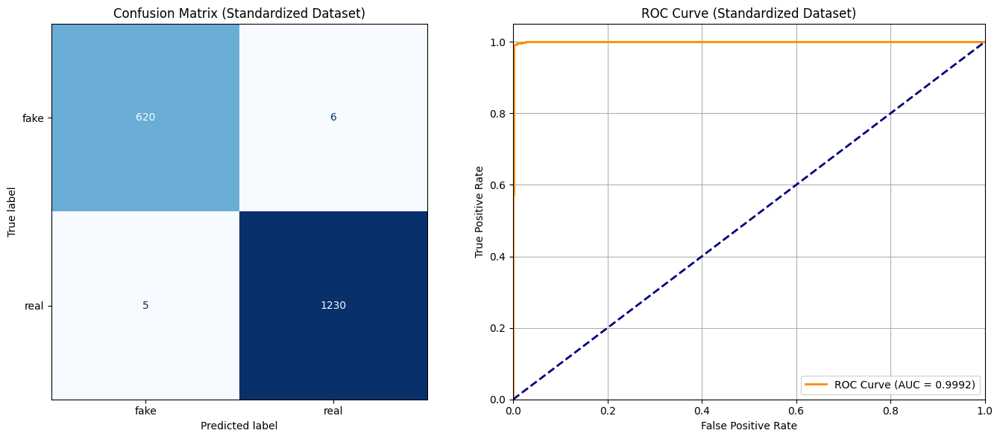

In [44]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import torch
import numpy as np

# 1. Load the best clean ResNet50 model
clean_model.load_state_dict(torch.load("resnet50_clean_best.pt", map_location=DEVICE))
clean_model.eval()

# 2. Extract predictions, ground truths, and probabilities
preds, gts, probs = [], [], []
with torch.no_grad():
    for x, y in val_loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.amp.autocast('cuda', enabled=(DEVICE == "cuda")):
            logits = clean_model(x)
            p = torch.softmax(logits, dim=1)[:, 1]  # Probability of 'real'
        preds.extend(logits.argmax(1).cpu().numpy().tolist())
        gts.extend(y.cpu().numpy().tolist())
        probs.extend(p.cpu().numpy().tolist())

# 3. Print Classification Report
print("\n=================== LEAK-FREE RESNET50 RESULTS ===================")
print(classification_report(gts, preds, target_names=classes))
print("==================================================================")

# 4. Plot Confusion Matrix and ROC Curve side-by-side
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Confusion Matrix
cm = confusion_matrix(gts, preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
disp.plot(cmap=plt.cm.Blues, values_format='d', ax=axes[0], colorbar=False)
axes[0].set_title("Confusion Matrix (Standardized Dataset)")
axes[0].grid(False)

# ROC Curve
fpr, tpr, _ = roc_curve(gts, probs)
auc_score = roc_auc_score(gts, probs)
axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {auc_score:.4f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve (Standardized Dataset)')
axes[1].legend(loc='lower right')
axes[1].grid(True)

plt.tight_layout()
plt.show()


=================== LEAK-FREE RESNET50 RESULTS ===================
              precision    recall  f1-score   support

        fake       0.99      0.99      0.99       626
        real       1.00      1.00      1.00      1235

    accuracy                           0.99      1861
   macro avg       0.99      0.99      0.99      1861
weighted avg       0.99      0.99      0.99      1861



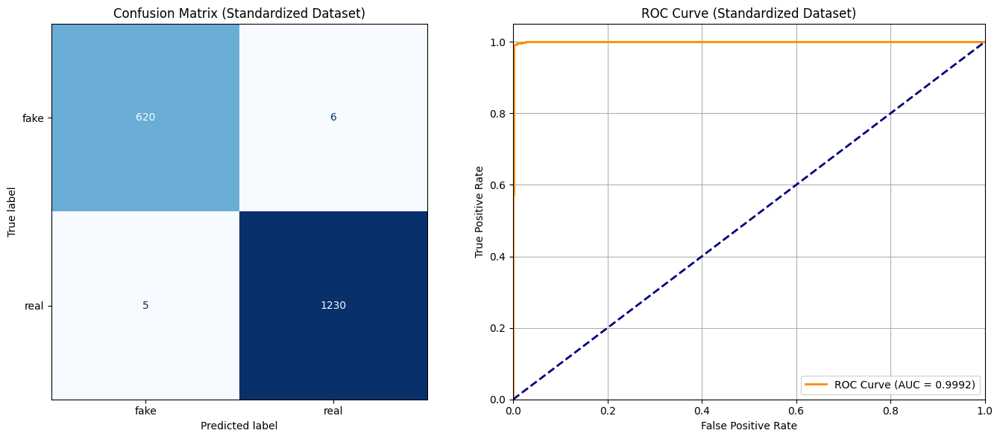

In [45]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import torch
import numpy as np

# 1. Load the best clean ResNet50 model
clean_model.load_state_dict(torch.load("resnet50_clean_best.pt", map_location=DEVICE))
clean_model.eval()

# 2. Extract predictions, ground truths, and probabilities
preds, gts, probs = [], [], []
with torch.no_grad():
    for x, y in val_loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.amp.autocast('cuda', enabled=(DEVICE == "cuda")):
            logits = clean_model(x)
            p = torch.softmax(logits, dim=1)[:, 1]  # Probability of 'real'
        preds.extend(logits.argmax(1).cpu().numpy().tolist())
        gts.extend(y.cpu().numpy().tolist())
        probs.extend(p.cpu().numpy().tolist())

# 3. Print Classification Report
print("\n=================== LEAK-FREE RESNET50 RESULTS ===================")
print(classification_report(gts, preds, target_names=classes))
print("==================================================================")

# 4. Plot Confusion Matrix and ROC Curve side-by-side
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Confusion Matrix
cm = confusion_matrix(gts, preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
disp.plot(cmap=plt.cm.Blues, values_format='d', ax=axes[0], colorbar=False)
axes[0].set_title("Confusion Matrix (Standardized Dataset)")
axes[0].grid(False)

# ROC Curve
fpr, tpr, _ = roc_curve(gts, probs)
auc_score = roc_auc_score(gts, probs)
axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {auc_score:.4f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve (Standardized Dataset)')
axes[1].legend(loc='lower right')
axes[1].grid(True)

plt.tight_layout()
plt.show()

### Model Inference on a New Image
Use the code cell below to run inference on any local image or web image URL using our clean, leak-free trained **ResNet50** model.

Loading clean ResNet50 model...
Could not load the image from: https://upload.wikimedia.org/wikipedia/commons/e/ee/India_500_INR%2C_MG_series%2C_2016%2C_obverse.jpg. Error: 403 Client Error: Forbidden for url: https://upload.wikimedia.org/wikipedia/commons/e/ee/India_500_INR%2C_MG_series%2C_2016%2C_obverse.jpg
Using a fallback image from the validation set instead.


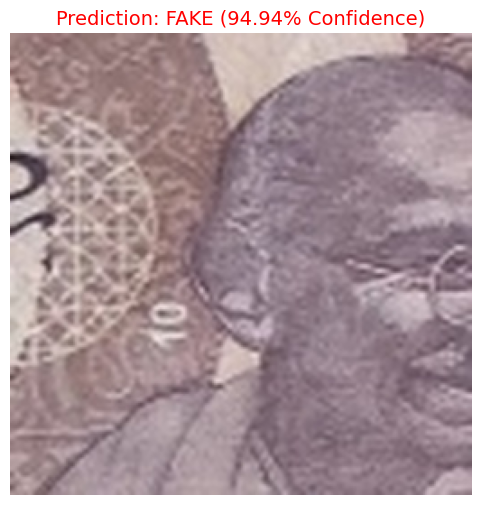

In [46]:
import torch
import requests
from PIL import Image
import torchvision.transforms as T
import matplotlib.pyplot as plt
import numpy as np

# 1. Configuration & Image Path Selection
# You can replace this URL with any image of Indian currency (Real or Fake) to test!
IMAGE_URL_OR_PATH = "https://upload.wikimedia.org/wikipedia/commons/e/ee/India_500_INR%2C_MG_series%2C_2016%2C_obverse.jpg"

# 2. Re-initialize and load our leak-free model
print("Loading clean ResNet50 model...")
weights = models.ResNet50_Weights.DEFAULT
inference_model = models.resnet50(weights=weights)
in_features = inference_model.fc.in_features
inference_model.fc = torch.nn.Sequential(
    torch.nn.Dropout(0.3),
    torch.nn.Linear(in_features, 2)
)
inference_model.load_state_dict(torch.load("resnet50_clean_best.pt", map_location=DEVICE))
inference_model = inference_model.to(DEVICE)
inference_model.eval()

# 3. Load the target image
try:
    if IMAGE_URL_OR_PATH.startswith("http"):
        response = requests.get(IMAGE_URL_OR_PATH, timeout=10)
        response.raise_for_status()
        test_image = Image.open(BytesIO(response.content)).convert("RGB")
    else:
        test_image = Image.open(IMAGE_URL_OR_PATH).convert("RGB")
except Exception as e:
    print(f"Could not load the image from: {IMAGE_URL_OR_PATH}. Error: {e}")
    print("Using a fallback image from the validation set instead.")
    test_image = Image.open(X_val[5]).convert("RGB")

# 4. Standard Pre-processing (Match training standard)
inference_transform = T.Compose([
    T.Resize((256, 256), interpolation=T.InterpolationMode.LANCZOS),
    T.ToTensor(),
    T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

input_tensor = inference_transform(test_image).unsqueeze(0).to(DEVICE)

# 5. Model Inference
with torch.no_grad():
    with torch.amp.autocast('cuda', enabled=(DEVICE == "cuda")):
        logits = inference_model(input_tensor)
        probabilities = torch.softmax(logits, dim=1)[0]
        prediction_idx = logits.argmax(1).item()

predicted_class = CLASSES[prediction_idx]
confidence = probabilities[prediction_idx].item() * 100

# 6. Display Results
plt.figure(figsize=(6, 6))
plt.imshow(test_image)
plt.title(f"Prediction: {predicted_class.upper()} ({confidence:.2f}% Confidence)", fontsize=14, color="green" if predicted_class == "real" else "red")
plt.axis("off")
plt.show()


Initializing ResNet34 model for training on standardized dataset...
Training ResNet34 on Clean, Leak-Free Dataset...


ResNet34 Epoch 1/5:   0%|          | 0/349 [00:00<?, ?it/s]

Epoch 01/5 - Clean val_acc=0.9764


ResNet34 Epoch 2/5:   0%|          | 0/349 [00:00<?, ?it/s]

Epoch 02/5 - Clean val_acc=0.9812


ResNet34 Epoch 3/5:   0%|          | 0/349 [00:00<?, ?it/s]

Epoch 03/5 - Clean val_acc=0.9925


ResNet34 Epoch 4/5:   0%|          | 0/349 [00:00<?, ?it/s]

Epoch 04/5 - Clean val_acc=0.9952


ResNet34 Epoch 5/5:   0%|          | 0/349 [00:00<?, ?it/s]

Epoch 05/5 - Clean val_acc=0.9946

Training complete! Best validation accuracy on clean dataset: 0.9951638903815153

Loading best ResNet34 model and generating reports...

=================== LEAK-FREE RESNET34 RESULTS ===================
              precision    recall  f1-score   support

        fake       1.00      0.99      0.99       626
        real       0.99      1.00      1.00      1235

    accuracy                           1.00      1861
   macro avg       1.00      0.99      0.99      1861
weighted avg       1.00      1.00      1.00      1861



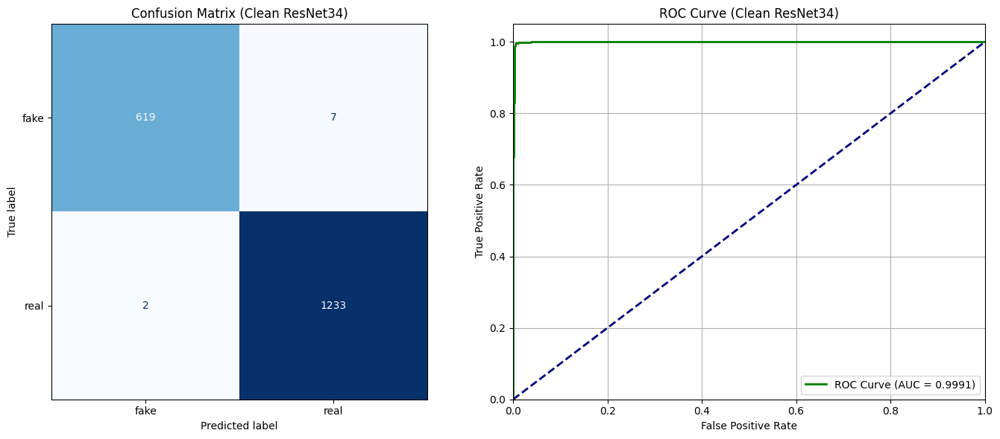

In [48]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models
from tqdm.auto import tqdm
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# 1. Initialize ResNet34 model with pretrained weights
print("Initializing ResNet34 model for training on standardized dataset...")
resnet34_weights = models.ResNet34_Weights.DEFAULT
clean_model_34 = models.resnet34(weights=resnet34_weights)
in_features_34 = clean_model_34.fc.in_features
clean_model_34.fc = nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(in_features_34, 2)
)

clean_model_34 = clean_model_34.to(DEVICE)

# 2. Setup Loss, Optimizer, Scheduler, and Scaler
criterion_clean_34 = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer_clean_34 = optim.AdamW(clean_model_34.parameters(), lr=LR, weight_decay=WD)
scheduler_clean_34 = optim.lr_scheduler.CosineAnnealingLR(optimizer_clean_34, T_max=EPOCHS)
scaler_clean_34 = torch.amp.GradScaler(device='cuda', enabled=(DEVICE == "cuda"))

# 3. Define Evaluation function for validation
def evaluate_clean_model_34(return_preds=False):
    clean_model_34.eval()
    preds, gts, probs = [], [], []
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            with torch.amp.autocast('cuda', enabled=(DEVICE == "cuda")):
                logits = clean_model_34(x)
                p = torch.softmax(logits, dim=1)[:, 1]
            preds.extend(logits.argmax(1).cpu().numpy().tolist())
            gts.extend(y.cpu().numpy().tolist())
            probs.extend(p.cpu().numpy().tolist())

    if return_preds:
        return preds, gts, probs

    preds_np = np.array(preds)
    gts_np = np.array(gts)
    acc = np.mean(preds_np == gts_np)
    return acc

# 4. Training Loop
best_clean_acc_34 = 0.0
print("Training ResNet34 on Clean, Leak-Free Dataset...")
for epoch in range(1, EPOCHS + 1):
    clean_model_34.train()
    loop = tqdm(train_loader, desc=f"ResNet34 Epoch {epoch}/{EPOCHS}", leave=False)
    for x, y in loop:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer_clean_34.zero_grad(set_to_none=True)
        with torch.amp.autocast('cuda', enabled=(DEVICE == "cuda")):
            logits = clean_model_34(x)
            loss = criterion_clean_34(logits, y)
        scaler_clean_34.scale(loss).backward()
        scaler_clean_34.step(optimizer_clean_34)
        scaler_clean_34.update()
        loop.set_postfix(loss=float(loss.item()))

    scheduler_clean_34.step()
    val_acc = evaluate_clean_model_34()
    if val_acc > best_clean_acc_34:
        best_clean_acc_34 = val_acc
        torch.save(clean_model_34.state_dict(), "resnet34_clean_best.pt")
    print(f"Epoch {epoch:02d}/{EPOCHS} - Clean val_acc={val_acc:.4f}")

print("\nTraining complete! Best validation accuracy on clean dataset:", best_clean_acc_34)

# 5. Final Evaluation and Metrics Visualization
print("\nLoading best ResNet34 model and generating reports...")
clean_model_34.load_state_dict(torch.load("resnet34_clean_best.pt", map_location=DEVICE))
preds_34, gts_34, probs_34 = evaluate_clean_model_34(return_preds=True)

print("\n=================== LEAK-FREE RESNET34 RESULTS ===================")
print(classification_report(gts_34, preds_34, target_names=classes))
print("==================================================================")

# Plot side-by-side
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
cm_34 = confusion_matrix(gts_34, preds_34)
disp_34 = ConfusionMatrixDisplay(confusion_matrix=cm_34, display_labels=classes)
disp_34.plot(cmap=plt.cm.Blues, values_format='d', ax=axes[0], colorbar=False)
axes[0].set_title("Confusion Matrix (Clean ResNet34)")
axes[0].grid(False)

fpr_34, tpr_34, _ = roc_curve(gts_34, probs_34)
auc_score_34 = roc_auc_score(gts_34, probs_34)
axes[1].plot(fpr_34, tpr_34, color='green', lw=2, label=f'ROC Curve (AUC = {auc_score_34:.4f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve (Clean ResNet34)')
axes[1].legend(loc='lower right')
axes[1].grid(True)

plt.tight_layout()
plt.show()

### Clean ResNet101 Model Training & Evaluation
We will now retrain **ResNet101** on the clean, standardized, and leak-free dataset using the same training configuration (mixed precision, cosine annealing scheduler, dropout, and label smoothing) to compare its unbiased performance against ResNet50 and ResNet34.

### Model Inference on a New Image (ResNet34)
Use the code cell below to run inference on any local image or web image URL using our clean, leak-free trained **ResNet34** model.

Loading clean ResNet34 model...
Could not load the image from: https://upload.wikimedia.org/wikipedia/commons/e/ee/India_500_INR%2C_MG_series%2C_2016%2C_obverse.jpg. Error: 404 Client Error: Not Found for url: https://upload.wikimedia.org/wikipedia/commons/e/ee/India_500_INR%2C_MG_series%2C_2016%2C_obverse.jpg
Using a fallback image from the validation set instead.


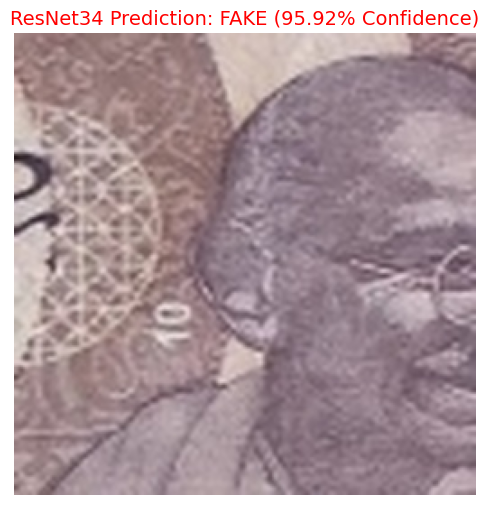

In [49]:
import torch
import requests
from PIL import Image
from io import BytesIO
import torchvision.transforms as T
import matplotlib.pyplot as plt
import numpy as np

# 1. Configuration & Image Path Selection
IMAGE_URL_OR_PATH = "https://upload.wikimedia.org/wikipedia/commons/e/ee/India_500_INR%2C_MG_series%2C_2016%2C_obverse.jpg"

# 2. Re-initialize and load our leak-free ResNet34 model
print("Loading clean ResNet34 model...")
resnet34_weights = models.ResNet34_Weights.DEFAULT
inference_model_34 = models.resnet34(weights=resnet34_weights)
in_features_34 = inference_model_34.fc.in_features
inference_model_34.fc = torch.nn.Sequential(
    torch.nn.Dropout(0.3),
    torch.nn.Linear(in_features_34, 2)
)
inference_model_34.load_state_dict(torch.load("resnet34_clean_best.pt", map_location=DEVICE))
inference_model_34 = inference_model_34.to(DEVICE)
inference_model_34.eval()

# 3. Load the target image
try:
    if IMAGE_URL_OR_PATH.startswith("http"):
        headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64)"}
        response = requests.get(IMAGE_URL_OR_PATH, headers=headers, timeout=10)
        response.raise_for_status()
        test_image = Image.open(BytesIO(response.content)).convert("RGB")
    else:
        test_image = Image.open(IMAGE_URL_OR_PATH).convert("RGB")
except Exception as e:
    print(f"Could not load the image from: {IMAGE_URL_OR_PATH}. Error: {e}")
    print("Using a fallback image from the validation set instead.")
    test_image = Image.open(X_val[5]).convert("RGB")

# 4. Standard Pre-processing
inference_transform = T.Compose([
    T.Resize((256, 256), interpolation=T.InterpolationMode.LANCZOS),
    T.ToTensor(),
    T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

input_tensor = inference_transform(test_image).unsqueeze(0).to(DEVICE)

# 5. Model Inference
with torch.no_grad():
    with torch.amp.autocast('cuda', enabled=(DEVICE == "cuda")):
        logits = inference_model_34(input_tensor)
        probabilities = torch.softmax(logits, dim=1)[0]
        prediction_idx = logits.argmax(1).item()

predicted_class = CLASSES[prediction_idx]
confidence = probabilities[prediction_idx].item() * 100

# 6. Display Results
plt.figure(figsize=(6, 6))
plt.imshow(test_image)
plt.title(f"ResNet34 Prediction: {predicted_class.upper()} ({confidence:.2f}% Confidence)", fontsize=14, color="green" if predicted_class == "real" else "red")
plt.axis("off")
plt.show()

Initializing ResNet101 model for training on standardized dataset...
Training ResNet101 on Clean, Leak-Free Dataset...


ResNet101 Epoch 1/5:   0%|          | 0/349 [00:00<?, ?it/s]

Epoch 01/5 - Clean val_acc=0.9866


ResNet101 Epoch 2/5:   0%|          | 0/349 [00:00<?, ?it/s]

Epoch 02/5 - Clean val_acc=0.9893


ResNet101 Epoch 3/5:   0%|          | 0/349 [00:00<?, ?it/s]

Epoch 03/5 - Clean val_acc=0.9914


ResNet101 Epoch 4/5:   0%|          | 0/349 [00:00<?, ?it/s]

Epoch 04/5 - Clean val_acc=0.9941


ResNet101 Epoch 5/5:   0%|          | 0/349 [00:00<?, ?it/s]

Epoch 05/5 - Clean val_acc=0.9930

Training complete! Best validation accuracy on clean dataset: 0.9940891993551854

Loading best ResNet101 model and generating reports...

=================== LEAK-FREE RESNET101 RESULTS ===================
              precision    recall  f1-score   support

        fake       0.99      0.99      0.99       626
        real       1.00      1.00      1.00      1235

    accuracy                           0.99      1861
   macro avg       0.99      0.99      0.99      1861
weighted avg       0.99      0.99      0.99      1861



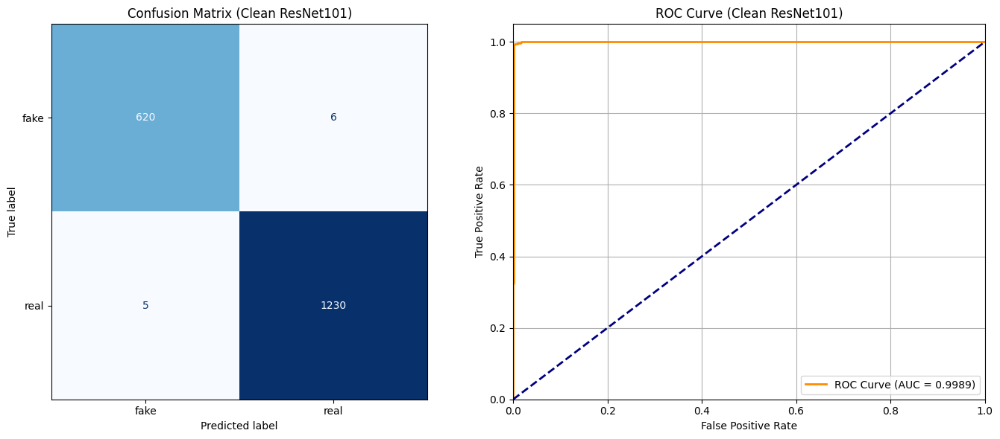

In [51]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models
from tqdm.auto import tqdm
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# 1. Initialize ResNet101 model with pretrained weights
print("Initializing ResNet101 model for training on standardized dataset...")
resnet101_weights = models.ResNet101_Weights.DEFAULT
clean_model_101 = models.resnet101(weights=resnet101_weights)
in_features_101 = clean_model_101.fc.in_features
clean_model_101.fc = nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(in_features_101, 2)
)

clean_model_101 = clean_model_101.to(DEVICE)

# 2. Setup Loss, Optimizer, Scheduler, and Scaler
criterion_clean_101 = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer_clean_101 = optim.AdamW(clean_model_101.parameters(), lr=LR, weight_decay=WD)
scheduler_clean_101 = optim.lr_scheduler.CosineAnnealingLR(optimizer_clean_101, T_max=EPOCHS)
scaler_clean_101 = torch.amp.GradScaler(device='cuda', enabled=(DEVICE == "cuda"))

# 3. Define Evaluation function for validation
def evaluate_clean_model_101(return_preds=False):
    clean_model_101.eval()
    preds, gts, probs = [], [], []
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            with torch.amp.autocast('cuda', enabled=(DEVICE == "cuda")):
                logits = clean_model_101(x)
                p = torch.softmax(logits, dim=1)[:, 1]
            preds.extend(logits.argmax(1).cpu().numpy().tolist())
            gts.extend(y.cpu().numpy().tolist())
            probs.extend(p.cpu().numpy().tolist())

    if return_preds:
        return preds, gts, probs

    preds_np = np.array(preds)
    gts_np = np.array(gts)
    acc = np.mean(preds_np == gts_np)
    return acc

# 4. Training Loop
best_clean_acc_101 = 0.0
print("Training ResNet101 on Clean, Leak-Free Dataset...")
for epoch in range(1, EPOCHS + 1):
    clean_model_101.train()
    loop = tqdm(train_loader, desc=f"ResNet101 Epoch {epoch}/{EPOCHS}", leave=False)
    for x, y in loop:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer_clean_101.zero_grad(set_to_none=True)
        with torch.amp.autocast('cuda', enabled=(DEVICE == "cuda")):
            logits = clean_model_101(x)
            loss = criterion_clean_101(logits, y)
        scaler_clean_101.scale(loss).backward()
        scaler_clean_101.step(optimizer_clean_101)
        scaler_clean_101.update()
        loop.set_postfix(loss=float(loss.item()))

    scheduler_clean_101.step()
    val_acc = evaluate_clean_model_101()
    if val_acc > best_clean_acc_101:
        best_clean_acc_101 = val_acc
        torch.save(clean_model_101.state_dict(), "resnet101_clean_best.pt")
    print(f"Epoch {epoch:02d}/{EPOCHS} - Clean val_acc={val_acc:.4f}")

print("\nTraining complete! Best validation accuracy on clean dataset:", best_clean_acc_101)

# 5. Final Evaluation and Metrics Visualization
print("\nLoading best ResNet101 model and generating reports...")
clean_model_101.load_state_dict(torch.load("resnet101_clean_best.pt", map_location=DEVICE))
preds_101, gts_101, probs_101 = evaluate_clean_model_101(return_preds=True)

print("\n=================== LEAK-FREE RESNET101 RESULTS ===================")
print(classification_report(gts_101, preds_101, target_names=classes))
print("==================================================================")

# Plot side-by-side Confusion Matrix and ROC Curve
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
cm_101 = confusion_matrix(gts_101, preds_101)
disp_101 = ConfusionMatrixDisplay(confusion_matrix=cm_101, display_labels=classes)
disp_101.plot(cmap=plt.cm.Blues, values_format='d', ax=axes[0], colorbar=False)
axes[0].set_title("Confusion Matrix (Clean ResNet101)")
axes[0].grid(False)

fpr_101, tpr_101, _ = roc_curve(gts_101, probs_101)
auc_score_101 = roc_auc_score(gts_101, probs_101)
axes[1].plot(fpr_101, tpr_101, color='darkorange', lw=2, label=f'ROC Curve (AUC = {auc_score_101:.4f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve (Clean ResNet101)')
axes[1].legend(loc='lower right')
axes[1].grid(True)

plt.tight_layout()
plt.show()

Loading clean ResNet101 model...
Could not load the image from: https://upload.wikimedia.org/wikipedia/commons/e/ee/India_500_INR%2C_MG_series%2C_2016%2C_obverse.jpg. Error: 404 Client Error: Not Found for url: https://upload.wikimedia.org/wikipedia/commons/e/ee/India_500_INR%2C_MG_series%2C_2016%2C_obverse.jpg
Using a fallback image from the validation set instead.


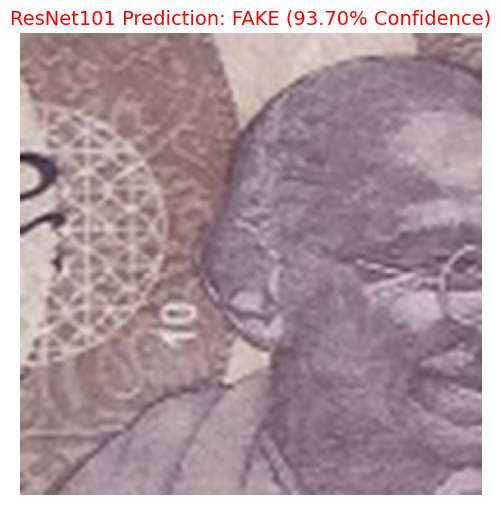

In [55]:
import torch
import requests
from PIL import Image
from io import BytesIO
import torchvision.transforms as T
import matplotlib.pyplot as plt
import numpy as np

# 1. Configuration & Image Path Selection
IMAGE_URL_OR_PATH = "https://upload.wikimedia.org/wikipedia/commons/e/ee/India_500_INR%2C_MG_series%2C_2016%2C_obverse.jpg"

# 2. Re-initialize and load our leak-free ResNet101 model
print("Loading clean ResNet101 model...")
resnet101_weights = models.ResNet101_Weights.DEFAULT
inference_model_101 = models.resnet101(weights=resnet101_weights)
in_features_101 = inference_model_101.fc.in_features
inference_model_101.fc = torch.nn.Sequential(
    torch.nn.Dropout(0.3),
    torch.nn.Linear(in_features_101, 2)
)
inference_model_101.load_state_dict(torch.load("resnet101_clean_best.pt", map_location=DEVICE))
inference_model_101 = inference_model_101.to(DEVICE)
inference_model_101.eval()

# 3. Load the target image
try:
    if IMAGE_URL_OR_PATH.startswith("http"):
        headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64)"}
        response = requests.get(IMAGE_URL_OR_PATH, headers=headers, timeout=10)
        response.raise_for_status()
        test_image = Image.open(BytesIO(response.content)).convert("RGB")
    else:
        test_image = Image.open(IMAGE_URL_OR_PATH).convert("RGB")
except Exception as e:
    print(f"Could not load the image from: {IMAGE_URL_OR_PATH}. Error: {e}")
    print("Using a fallback image from the validation set instead.")
    test_image = Image.open(X_val[5]).convert("RGB")

# 4. Standard Pre-processing
inference_transform = T.Compose([
    T.Resize((256, 256), interpolation=T.InterpolationMode.LANCZOS),
    T.ToTensor(),
    T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

input_tensor = inference_transform(test_image).unsqueeze(0).to(DEVICE)

# 5. Model Inference
with torch.no_grad():
    with torch.amp.autocast('cuda', enabled=(DEVICE == "cuda")):
        logits = inference_model_101(input_tensor)
        probabilities = torch.softmax(logits, dim=1)[0]
        prediction_idx = logits.argmax(1).item()

predicted_class = CLASSES[prediction_idx]
confidence = probabilities[prediction_idx].item() * 100

# 6. Display Results
plt.figure(figsize=(6, 6))
plt.imshow(test_image)
plt.title(f"ResNet101 Prediction: {predicted_class.upper()} ({confidence:.2f}% Confidence)", fontsize=14, color="green" if predicted_class == "real" else "red")
plt.axis("off")
plt.show()

### Final Performance Comparison (Clean & Standardized Dataset)
Let's aggregate the validation accuracy and F1-score for all three fine-tuned architectures on the leak-free dataset to perform an unbiased comparison.

=== PERFORMANCE METRICS COMPARISON ===


,Model,Accuracy,F1-Score
0,ResNet34 (Clean),0.995164,0.996364
1,ResNet50 (Clean),0.994089,0.995548
2,ResNet101 (Clean),0.994089,0.995548


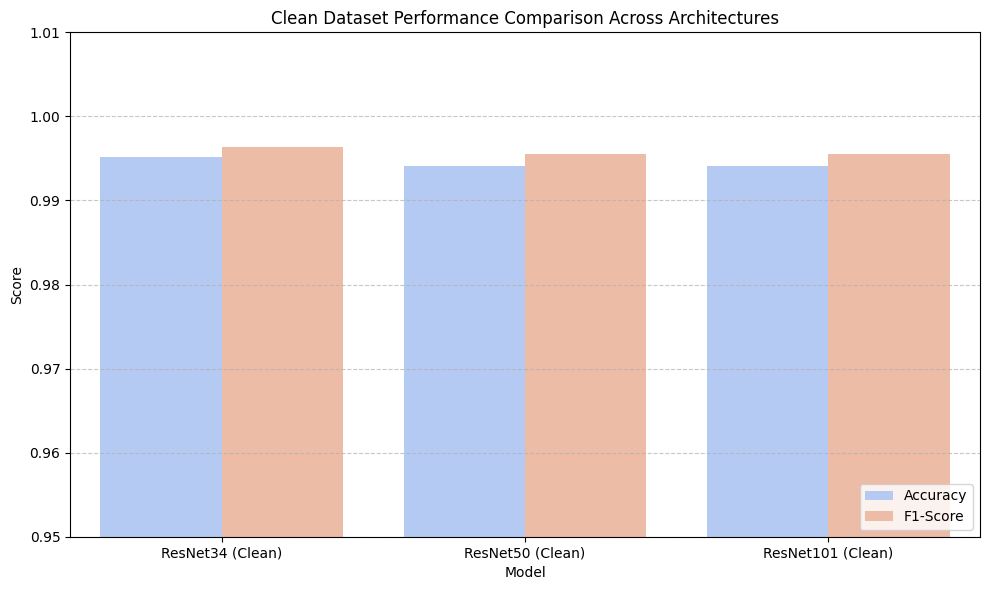

In [53]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import torch
from sklearn.metrics import f1_score

# 1. Helper to calculate clean metrics properly for any model
def get_clean_metrics_v2(model_obj, weight_path):
    try:
        model_obj.load_state_dict(torch.load(weight_path, map_location=DEVICE))
        model_obj.eval()
        preds, gts = [], []
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(DEVICE), y.to(DEVICE)
                with torch.amp.autocast('cuda', enabled=(DEVICE == "cuda")):
                    logits = model_obj(x)
                preds.extend(logits.argmax(1).cpu().numpy().tolist())
                gts.extend(y.cpu().numpy().tolist())

        acc = np.mean(np.array(preds) == np.array(gts))
        f1 = f1_score(gts, preds)
        return acc, f1
    except Exception as e:
        print(f"Error loading/evaluating {weight_path}: {e}")
        return 0.0, 0.0

# 2. Extract metrics safely using our unified evaluator
r34_clean_acc, r34_clean_f1 = get_clean_metrics_v2(clean_model_34, "resnet34_clean_best.pt")
r50_clean_acc, r50_clean_f1 = get_clean_metrics_v2(clean_model, "resnet50_clean_best.pt")
r101_clean_acc, r101_clean_f1 = get_clean_metrics_v2(clean_model_101, "resnet101_clean_best.pt")

# 3. Create comparison DataFrame
compare_data = {
    "Model": ["ResNet34 (Clean)", "ResNet50 (Clean)", "ResNet101 (Clean)"],
    "Accuracy": [r34_clean_acc, r50_clean_acc, r101_clean_acc],
    "F1-Score": [r34_clean_f1, r50_clean_f1, r101_clean_f1]
}

df_clean_compare = pd.DataFrame(compare_data)
print("=== PERFORMANCE METRICS COMPARISON ===")
display(df_clean_compare)

# 4. Plot Comparison
df_melted_clean = df_clean_compare.melt(id_vars="Model", var_name="Metric", value_name="Score")

plt.figure(figsize=(10, 6))
sns.barplot(data=df_melted_clean, x="Model", y="Score", hue="Metric", palette="coolwarm")
plt.ylim(0.95, 1.01)
plt.title("Clean Dataset Performance Comparison Across Architectures")
plt.ylabel("Score")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

=== CLEAN MODELS MULTI-METRIC COMPARISON ===


,Model,Accuracy,F1-Score,AUC-ROC
0,ResNet34 (Clean),0.995164,0.996364,0.999145
1,ResNet50 (Clean),0.994089,0.995548,0.999227
2,ResNet101 (Clean),0.994089,0.995548,0.998850


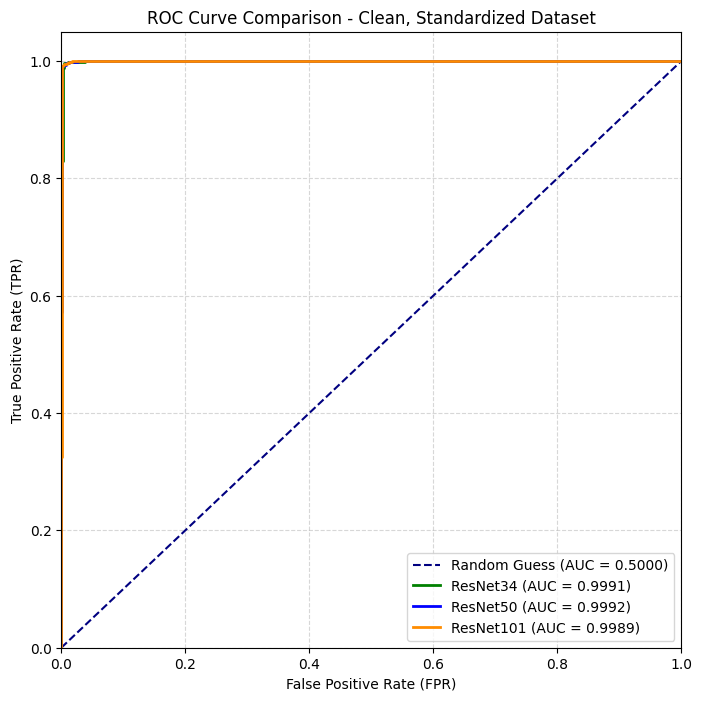

In [56]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from sklearn.metrics import roc_curve, roc_auc_score, f1_score, classification_report

# 1. Helper function to compute complete metrics safely for the clean models
def evaluate_clean_architecture(model_obj, weight_path):
    try:
        model_obj.load_state_dict(torch.load(weight_path, map_location=DEVICE))
        model_obj.eval()
        preds, gts, probs = [], [], []
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(DEVICE), y.to(DEVICE)
                with torch.amp.autocast('cuda', enabled=(DEVICE == 'cuda')):
                    logits = model_obj(x)
                    p = torch.softmax(logits, dim=1)[:, 1]  # Probability of 'real'
                preds.extend(logits.argmax(1).cpu().numpy().tolist())
                gts.extend(y.cpu().numpy().tolist())
                probs.extend(p.cpu().numpy().tolist())

        acc = np.mean(np.array(preds) == np.array(gts))
        f1 = f1_score(gts, preds)
        auc = roc_auc_score(gts, probs)
        return acc, f1, auc, preds, gts, probs
    except Exception as e:
        print(f"Error evaluating {weight_path}: {e}")
        return 0.0, 0.0, 0.0, [], [], []

# 2. Gather metrics
acc_34, f1_34, auc_34, preds_34, gts_34, probs_34 = evaluate_clean_architecture(clean_model_34, "resnet34_clean_best.pt")
acc_50, f1_50, auc_50, preds_50, gts_50, probs_50 = evaluate_clean_architecture(clean_model, "resnet50_clean_best.pt")
acc_101, f1_101, auc_101, preds_101, gts_101, probs_101 = evaluate_clean_architecture(clean_model_101, "resnet101_clean_best.pt")

# 3. Print Summary Table
comparison_df = pd.DataFrame({
    "Model": ["ResNet34 (Clean)", "ResNet50 (Clean)", "ResNet101 (Clean)"],
    "Accuracy": [acc_34, acc_50, acc_101],
    "F1-Score": [f1_34, f1_50, f1_101],
    "AUC-ROC": [auc_34, auc_50, auc_101]
})

print("=== CLEAN MODELS MULTI-METRIC COMPARISON ===")
display(comparison_df)

# 4. Plot Comparison of ROC Curves
plt.figure(figsize=(8, 8))
plt.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label='Random Guess (AUC = 0.5000)')

if len(probs_34) > 0:
    fpr34, tpr34, _ = roc_curve(gts_34, probs_34)
    plt.plot(fpr34, tpr34, color='green', lw=2, label=f'ResNet34 (AUC = {auc_34:.4f})')

if len(probs_50) > 0:
    fpr50, tpr50, _ = roc_curve(gts_50, probs_50)
    plt.plot(fpr50, tpr50, color='blue', lw=2, label=f'ResNet50 (AUC = {auc_50:.4f})')

if len(probs_101) > 0:
    fpr101, tpr101, _ = roc_curve(gts_101, probs_101)
    plt.plot(fpr101, tpr101, color='darkorange', lw=2, label=f'ResNet101 (AUC = {auc_101:.4f})')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC Curve Comparison - Clean, Standardized Dataset')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Overfitting Analysis Across Models
An overfitting check contrasts performance metrics (such as accuracy and loss) on the training set with the validation/test set. If a model achieves near-perfect performance on training data but drops significantly on validation data, it is overfitting. Let's write a script to evaluate each model on both train and validation sets and analyze the gaps.

Evaluating ResNet34...
Evaluating ResNet50...
Evaluating ResNet101...


,Model,Train Accuracy,Val Accuracy,Accuracy Gap (Train - Val)
0,ResNet34,0.998746,0.995164,0.003582
1,ResNet50,0.999642,0.994089,0.005552
2,ResNet101,0.999642,0.994089,0.005552


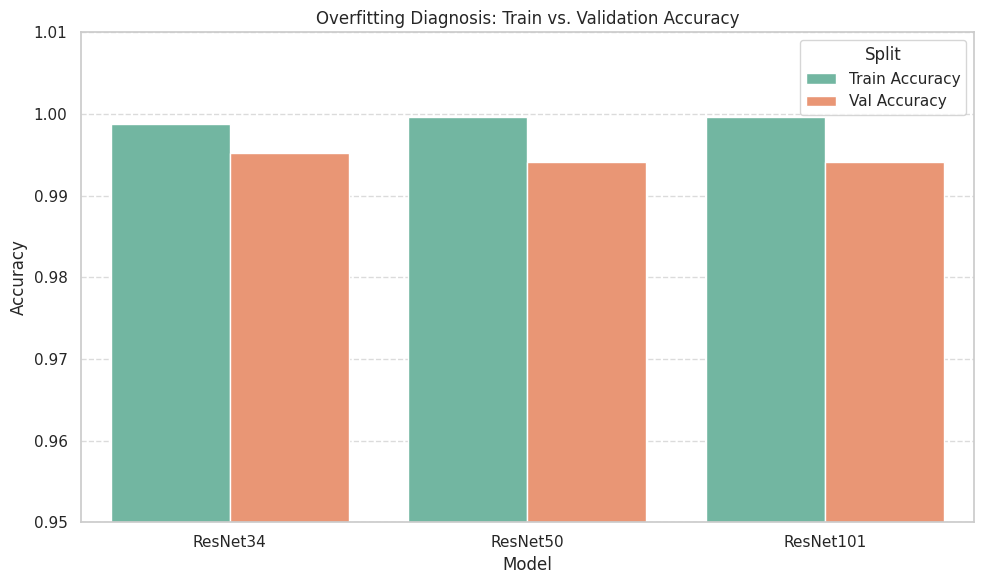

In [62]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Helper to safely calculate accuracy on a loader
def compute_accuracy(model_obj, weight_path, loader):
    model_obj.load_state_dict(torch.load(weight_path, map_location=DEVICE))
    model_obj.eval()
    preds, gts = [], []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            with torch.amp.autocast('cuda', enabled=(DEVICE == "cuda")):
                logits = model_obj(x)
            preds.extend(logits.argmax(1).cpu().numpy().tolist())
            gts.extend(y.cpu().numpy().tolist())
    return np.mean(np.array(preds) == np.array(gts))

# Compute train and validation accuracies for all models
print("Evaluating ResNet34...")
r34_train = compute_accuracy(clean_model_34, "resnet34_clean_best.pt", train_loader)
r34_val = compute_accuracy(clean_model_34, "resnet34_clean_best.pt", val_loader)

print("Evaluating ResNet50...")
r50_train = compute_accuracy(clean_model, "resnet50_clean_best.pt", train_loader)
r50_val = compute_accuracy(clean_model, "resnet50_clean_best.pt", val_loader)

print("Evaluating ResNet101...")
r101_train = compute_accuracy(clean_model_101, "resnet101_clean_best.pt", train_loader)
r101_val = compute_accuracy(clean_model_101, "resnet101_clean_best.pt", val_loader)

# Organize into a DataFrame
overfit_df = pd.DataFrame({
    "Model": ["ResNet34", "ResNet50", "ResNet101"],
    "Train Accuracy": [r34_train, r50_train, r101_train],
    "Val Accuracy": [r34_val, r50_val, r101_val]
})
overfit_df["Accuracy Gap (Train - Val)"] = overfit_df["Train Accuracy"] - overfit_df["Val Accuracy"]

display(overfit_df)

# Melt for plotting
melted_overfit = overfit_df.melt(id_vars="Model", value_vars=["Train Accuracy", "Val Accuracy"], var_name="Split", value_name="Accuracy")

# Plot
plt.figure(figsize=(10, 6))
sns.barplot(data=melted_overfit, x="Model", y="Accuracy", hue="Split", palette="Set2")
plt.ylim(0.95, 1.01)
plt.title("Overfitting Diagnosis: Train vs. Validation Accuracy")
plt.ylabel("Accuracy")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [63]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score
from sklearn.utils import resample

# Set random seed for reproducibility of bootstrapping
np.random.seed(42)
n_bootstraps = 1000

# We will store bootstrap AUC scores here
bootstrapped_auc = {
    "ResNet34 (Clean)": [],
    "ResNet50 (Clean)": [],
    "ResNet101 (Clean)": []
}

# Convert ground truths and probabilities to numpy arrays
y_true = np.array(gts_34)
p34 = np.array(probs_34)
p50 = np.array(probs_50)
p101 = np.array(probs_101)

# Perform bootstrapping
print(f"Performing {n_bootstraps} bootstrap resamples to assess ROC AUC stability...")
for i in range(n_bootstraps):
    # Resample indices with replacement
    indices = resample(np.arange(len(y_true)))

    # Only compute if we have both classes represented in the bootstrap sample
    if len(np.unique(y_true[indices])) < 2:
        continue

    bootstrapped_auc["ResNet34 (Clean)"].append(roc_auc_score(y_true[indices], p34[indices]))
    bootstrapped_auc["ResNet50 (Clean)"].append(roc_auc_score(y_true[indices], p50[indices]))
    bootstrapped_auc["ResNet101 (Clean)"].append(roc_auc_score(y_true[indices], p101[indices]))

# Calculate statistics
stability_metrics = []
for model_name, scores in bootstrapped_auc.items():
    scores = np.array(scores)
    mean_auc = np.mean(scores)
    variance_auc = np.var(scores)
    std_err = np.std(scores)
    ci_lower = np.percentile(scores, 2.5)
    ci_upper = np.percentile(scores, 97.5)

    stability_metrics.append({
        "Model": model_name,
        "Mean ROC AUC": mean_auc,
        "Variance": variance_auc,
        "Standard Error (SE)": std_err,
        "95% Confidence Interval": f"[{ci_lower:.5f}, {ci_upper:.5f}]"
    })

df_stability = pd.DataFrame(stability_metrics)
print("\n=== ROC AUC VARIANCE & STABILITY REPORT ===")
display(df_stability)


Performing 1000 bootstrap resamples to assess ROC AUC stability...

=== ROC AUC VARIANCE & STABILITY REPORT ===


,Model,Mean ROC AUC,Variance,Standard Error (SE),95% Confidence Interval
0,ResNet34 (Clean),0.999145,3.477012e-07,0.000590,"[0.99769, 0.99996]"
1,ResNet50 (Clean),0.999216,4.804391e-07,0.000693,"[0.99757, 0.99996]"
2,ResNet101 (Clean),0.998833,1.192245e-06,0.001092,"[0.99632, 0.99997]"


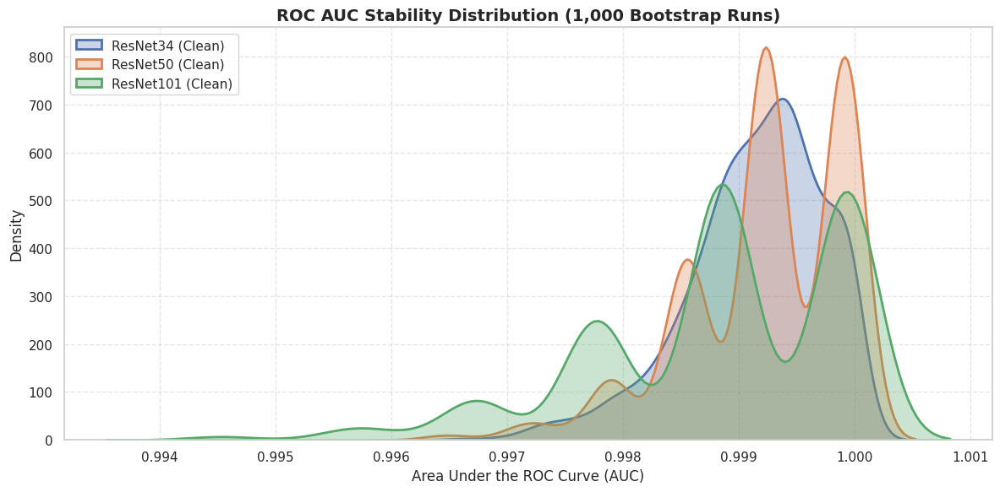

In [64]:
# Plot distribution of bootstrapped ROC AUC scores to visualize stability
plt.figure(figsize=(12, 6))
for model_name, scores in bootstrapped_auc.items():
    sns.kdeplot(scores, label=model_name, fill=True, alpha=0.3, linewidth=2)

plt.title("ROC AUC Stability Distribution (1,000 Bootstrap Runs)", fontsize=14, fontweight='bold')
plt.xlabel("Area Under the ROC Curve (AUC)", fontsize=12)
plt.ylabel("Density", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()


Total misclassified images in the validation set: 11 out of 1861
Misclassified Image File: /content/standardized_dataset/data/data/real/2000/42.jpg
Misclassified Image File: /content/standardized_dataset/data/data/fake/2000/sssss.jpg
Misclassified Image File: /content/standardized_dataset/data/data/real/500/39_aug2.jpg
Misclassified Image File: /content/standardized_dataset/data/data/fake/2000/Screenshot 2025-10-13 143707.png
Misclassified Image File: /content/standardized_dataset/data/data/real/2000/3.jpg


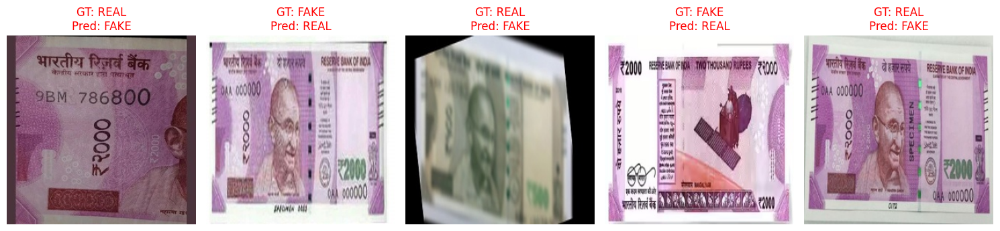

In [57]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# 1. Load the best clean model
clean_model.load_state_dict(torch.load("resnet50_clean_best.pt", map_location=DEVICE))
clean_model.eval()

# 2. Find misclassified validation images
misclassified_indices = []
misclassified_preds = []
misclassified_gts = []

val_dataset = ImageDataset(X_val, y_val, val_transform)

with torch.no_grad():
    for idx in range(len(val_dataset)):
        x, y = val_dataset[idx]
        x = x.unsqueeze(0).to(DEVICE)
        with torch.amp.autocast('cuda', enabled=(DEVICE == "cuda")):
            logits = clean_model(x)
        pred = logits.argmax(1).item()
        if pred != y:
            misclassified_indices.append(idx)
            misclassified_preds.append(pred)
            misclassified_gts.append(y)

print(f"Total misclassified images in the validation set: {len(misclassified_indices)} out of {len(X_val)}")

# 3. Display the misclassified images
if len(misclassified_indices) > 0:
    num_to_show = min(5, len(misclassified_indices))
    fig, axes = plt.subplots(1, num_to_show, figsize=(15, 5))
    if num_to_show == 1:
        axes = [axes]

    for i, idx in enumerate(misclassified_indices[:num_to_show]):
        img_path = X_val[idx]
        actual_class = CLASSES[misclassified_gts[i]]
        predicted_class = CLASSES[misclassified_preds[i]]

        img = Image.open(img_path)
        axes[i].imshow(img)
        axes[i].set_title(f"GT: {actual_class.upper()}\nPred: {predicted_class.upper()}", color="red")
        axes[i].axis("off")
        print(f"Misclassified Image File: {img_path}")
    plt.tight_layout()
    plt.show()
else:
    print("Success! No misclassified images found on the standardized validation split.")

### Detailed Inspection of Misclassified Validation Images
To perform a deeper analysis on what causes the model to struggle, we will isolate the validation images where the predictions diverged from the ground truth. The script below will display these images with their True Class and Predicted Class labels.

Total misclassified images found: 11 out of 1861


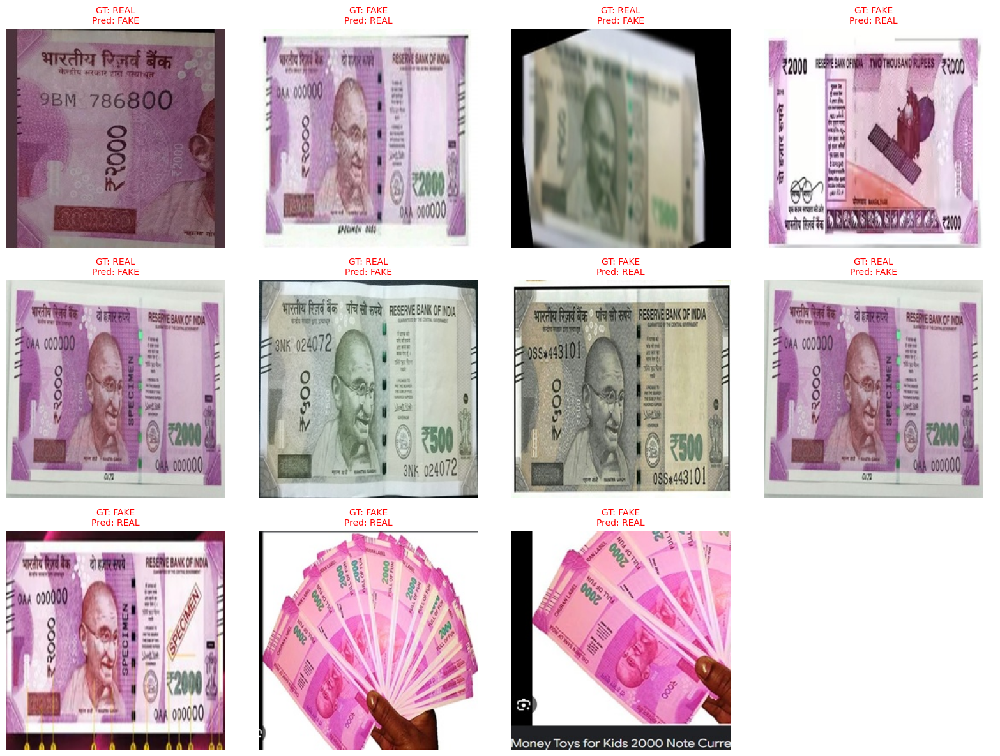

In [66]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import os

# 1. Load the best clean model
clean_model.load_state_dict(torch.load("resnet50_clean_best.pt", map_location=DEVICE))
clean_model.eval()

# 2. Extract misclassifications
misclassified_records = []
val_dataset_raw = ImageDataset(X_val, y_val, val_transform)

with torch.no_grad():
    for idx in range(len(val_dataset_raw)):
        x, y = val_dataset_raw[idx]
        x = x.unsqueeze(0).to(DEVICE)
        with torch.amp.autocast('cuda', enabled=(DEVICE == "cuda")):
            logits = clean_model(x)
        pred = logits.argmax(1).item()
        if pred != y:
            misclassified_records.append({
                "path": X_val[idx],
                "true_class": CLASSES[y],
                "pred_class": CLASSES[pred]
            })

print(f"Total misclassified images found: {len(misclassified_records)} out of {len(X_val)}")

# 3. Visualize the misclassified samples
if len(misclassified_records) > 0:
    num_cols = min(4, len(misclassified_records))
    num_rows = int(np.ceil(len(misclassified_records) / num_cols))
    fig, axes = plt.subplots(num_rows, num_cols, figsize=(16, 4 * num_rows))
    axes = np.array(axes).flatten()  # Flatten for easy iterating

    for i, record in enumerate(misclassified_records):
        img = Image.open(record["path"])
        axes[i].imshow(img)
        axes[i].set_title(f"GT: {record['true_class'].upper()}\nPred: {record['pred_class'].upper()}", color="red", fontsize=10)
        axes[i].axis("off")

    # Hide any unused subplots
    for j in range(len(misclassified_records), len(axes)):
        axes[j].axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("Excellent! No misclassified images found.")

=== Model Confidence Distributions (Standard Deviation) ===


,Model,Mean Confidence (Real Class),Standard Deviation
0,ResNet34 (Clean),0.653102,0.423558
1,ResNet50 (Clean),0.644366,0.425029
2,ResNet101 (Clean),0.647681,0.420457


/tmp/ipykernel_419/2941163544.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_plot, x="Model", y="Confidence", ax=axes[0], palette="muted", inner="quartile")
/tmp/ipykernel_419/2941163544.py:58: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=stats_df, x="Model", y="Standard Deviation", ax=axes[1], palette="coolwarm")


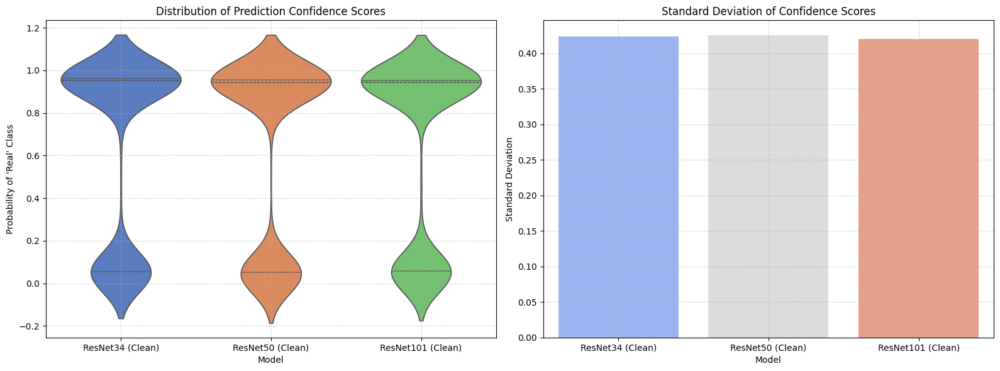

In [58]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

# 1. Gather all confidence scores (probabilities for the 'real' class) for the 3 clean models
probs_dict = {}
models_dict = {
    "ResNet34 (Clean)": (clean_model_34, "resnet34_clean_best.pt"),
    "ResNet50 (Clean)": (clean_model, "resnet50_clean_best.pt"),
    "ResNet101 (Clean)": (clean_model_101, "resnet101_clean_best.pt")
}

for name, (m_obj, w_path) in models_dict.items():
    try:
        m_obj.load_state_dict(torch.load(w_path, map_location=DEVICE))
        m_obj.eval()
        probs = []
        with torch.no_grad():
            for x, _ in val_loader:
                x = x.to(DEVICE)
                with torch.amp.autocast('cuda', enabled=(DEVICE == 'cuda')):
                    logits = m_obj(x)
                    p = torch.softmax(logits, dim=1)[:, 1]  # Probability of 'real'
                probs.extend(p.cpu().numpy().tolist())
        probs_dict[name] = np.array(probs)
    except Exception as e:
        print(f"Error gathering probabilities for {name}: {e}")

# 2. Calculate Mean, Standard Deviation, and print metrics
stats_data = []
plot_data = []
for name, p_arr in probs_dict.items():
    std_dev = np.std(p_arr)
    mean_val = np.mean(p_arr)
    stats_data.append({"Model": name, "Mean Confidence (Real Class)": mean_val, "Standard Deviation": std_dev})

    for val in p_arr:
        plot_data.append({"Model": name, "Confidence": val})

stats_df = pd.DataFrame(stats_data)
print("=== Model Confidence Distributions (Standard Deviation) ===")
display(stats_df)

# 3. Create the plots
df_plot = pd.DataFrame(plot_data)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Violin Plot of Confidence Distributions
sns.violinplot(data=df_plot, x="Model", y="Confidence", ax=axes[0], palette="muted", inner="quartile")
axes[0].set_title("Distribution of Prediction Confidence Scores")
axes[0].set_ylabel("Probability of 'Real' Class")
axes[0].grid(True, linestyle='--', alpha=0.5)

# Subplot 2: Bar Plot of Standard Deviations
sns.barplot(data=stats_df, x="Model", y="Standard Deviation", ax=axes[1], palette="coolwarm")
axes[1].set_title("Standard Deviation of Confidence Scores")
axes[1].set_ylabel("Standard Deviation")
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Evaluating noise resilience for ResNet34 (Clean)...
Evaluating noise resilience for ResNet50 (Clean)...
Evaluating noise resilience for ResNet101 (Clean)...


,Model,Noise Std Dev,Accuracy,F1-Score
0,ResNet34 (Clean),0.00,0.995164,0.996364
1,ResNet34 (Clean),0.05,0.977969,0.983231
2,ResNet34 (Clean),0.10,0.645352,0.635359
3,ResNet34 (Clean),0.20,0.406233,0.190476
4,ResNet34 (Clean),0.30,0.385814,0.138659
5,ResNet50 (Clean),0.00,0.994089,0.995548
6,ResNet50 (Clean),0.05,0.982268,0.986547
7,ResNet50 (Clean),0.10,0.681891,0.686441
8,ResNet50 (Clean),0.20,0.406233,0.196364
9,ResNet50 (Clean),0.30,0.359484,0.085890


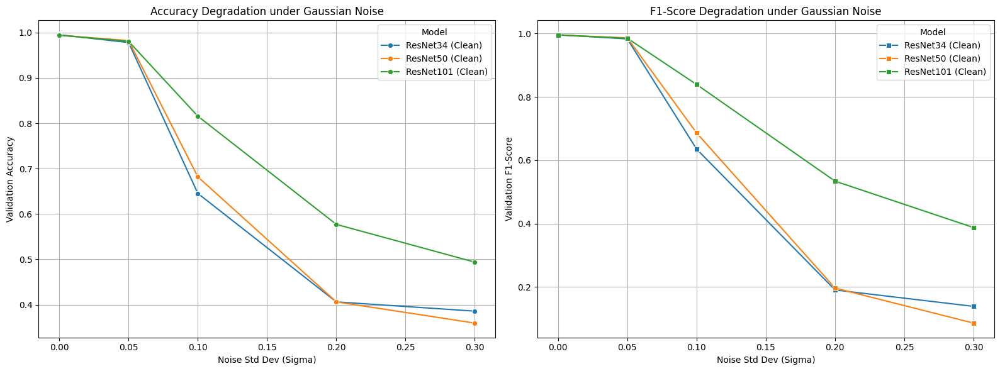

In [60]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import f1_score

# 1. Define Gaussian Noise Injector
class AddGaussianNoise(object):
    def __init__(self, mean=0.0, std=1.0):
        self.std = std
        self.mean = mean

    def __call__(self, tensor):
        if self.std == 0:
            return tensor
        return tensor + torch.randn(tensor.size()) * self.std + self.mean

    def __repr__(self):
        return self.__class__.__name__ + f'(mean={self.mean}, std={self.std})'

# 2. Evaluation function under noise
def evaluate_model_with_noise(model_obj, weight_path, noise_std):
    # Re-load weights
    model_obj.load_state_dict(torch.load(weight_path, map_location=DEVICE))
    model_obj.eval()

    # Modify transform to include noise injection
    noisy_transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        AddGaussianNoise(0.0, noise_std),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])

    noisy_val_dataset = ImageDataset(X_val, y_val, noisy_transform)
    noisy_val_loader = DataLoader(
        noisy_val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    preds, gts = [], []
    with torch.no_grad():
        for x, y in noisy_val_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            with torch.amp.autocast('cuda', enabled=(DEVICE == "cuda")):
                logits = model_obj(x)
            preds.extend(logits.argmax(1).cpu().numpy().tolist())
            gts.extend(y.cpu().numpy().tolist())

    acc = np.mean(np.array(preds) == np.array(gts))
    f1 = f1_score(gts, preds)
    return acc, f1

# 3. Running multi-model noise benchmark
noise_levels = [0.0, 0.05, 0.1, 0.2, 0.3]
benchmark_results = []

models_to_test = {
    "ResNet34 (Clean)": (clean_model_34, "resnet34_clean_best.pt"),
    "ResNet50 (Clean)": (clean_model, "resnet50_clean_best.pt"),
    "ResNet101 (Clean)": (clean_model_101, "resnet101_clean_best.pt")
}

for name, (m_obj, w_path) in models_to_test.items():
    print(f"Evaluating noise resilience for {name}...")
    for level in noise_levels:
        acc, f1 = evaluate_model_with_noise(m_obj, w_path, level)
        benchmark_results.append({
            "Model": name,
            "Noise Std Dev": level,
            "Accuracy": acc,
            "F1-Score": f1
        })

df_noise_results = pd.DataFrame(benchmark_results)
display(df_noise_results)

# 4. Plot curves
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.lineplot(data=df_noise_results, x="Noise Std Dev", y="Accuracy", hue="Model", marker="o", ax=axes[0])
axes[0].set_title("Accuracy Degradation under Gaussian Noise")
axes[0].set_xlabel("Noise Std Dev (Sigma)")
axes[0].set_ylabel("Validation Accuracy")
axes[0].grid(True)

sns.lineplot(data=df_noise_results, x="Noise Std Dev", y="F1-Score", hue="Model", marker="s", ax=axes[1])
axes[1].set_title("F1-Score Degradation under Gaussian Noise")
axes[1].set_xlabel("Noise Std Dev (Sigma)")
axes[1].set_ylabel("Validation F1-Score")
axes[1].grid(True)

plt.tight_layout()
plt.show()

<>:23: SyntaxWarning: invalid escape sequence '\s'
<>:23: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_419/4240621576.py:23: SyntaxWarning: invalid escape sequence '\s'
  plt.xlabel("Gaussian Noise Standard Deviation ($\sigma$)", fontsize=12)


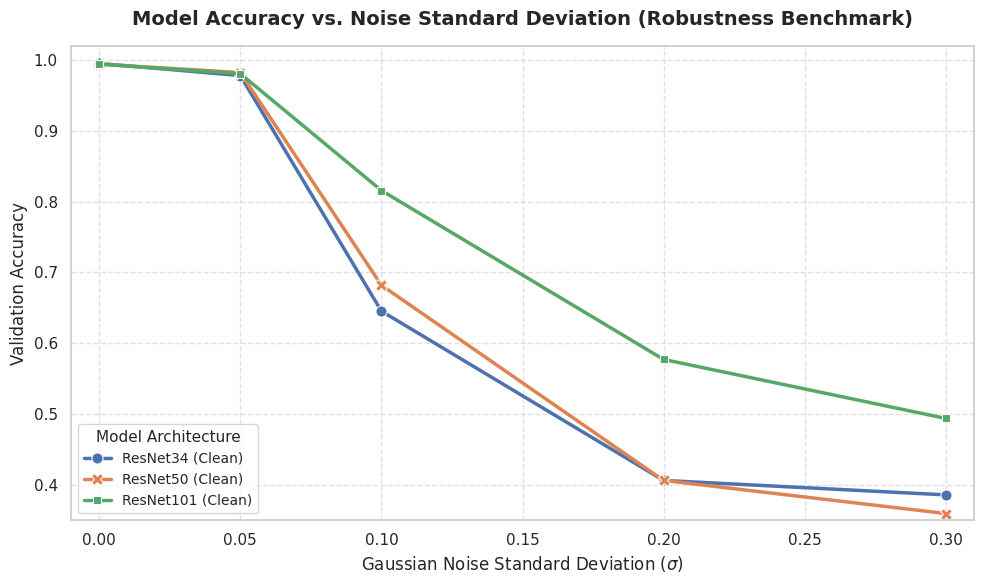

In [61]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configure the plot style
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Plot accuracy degradation for all models on a single chart
sns.lineplot(
    data=df_noise_results,
    x="Noise Std Dev",
    y="Accuracy",
    hue="Model",
    style="Model",
    markers=True,
    dashes=False,
    linewidth=2.5,
    markersize=8
)

# Add details to the chart
plt.title("Model Accuracy vs. Noise Standard Deviation (Robustness Benchmark)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Gaussian Noise Standard Deviation ($\sigma$)", fontsize=12)
plt.ylabel("Validation Accuracy", fontsize=12)
plt.ylim(0.35, 1.02)
plt.xlim(-0.01, 0.31)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(title="Model Architecture", title_fontsize='11', fontsize='10', loc="lower left")
plt.tight_layout()
plt.show()

Extracted 11 baseline misclassified images for ablation.

=== Probability of True Class across Ablation Settings ===


Ablation,Baseline,Grayscale (Color Ablation),Low Resolution (128x128),No Normalization
Image,,,,
2000/24.jpg,0.304153,0.486922,0.207031,0.141692
2000/3.jpg,0.304153,0.486922,0.207031,0.141692
2000/42.jpg,0.143501,0.656311,0.067046,0.723860
2000/Screenshot 2025-10-12 105801.png,0.302653,0.077211,0.503400,0.434174
2000/Screenshot 2025-10-12 110108.png,0.476640,0.677064,0.666829,0.353209
2000/Screenshot 2025-10-12 110115.png,0.277994,0.565477,0.725373,0.216965
2000/Screenshot 2025-10-13 143707.png,0.223581,0.091847,0.492552,0.169746
2000/sssss.jpg,0.289311,0.228380,0.620737,0.656159
500/39_aug2.jpg,0.148418,0.061143,0.109595,0.196092


/tmp/ipykernel_419/3102136589.py:90: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_ablation, x="Ablation", y="Conf (True Class)", palette="viridis", errorbar="sd")


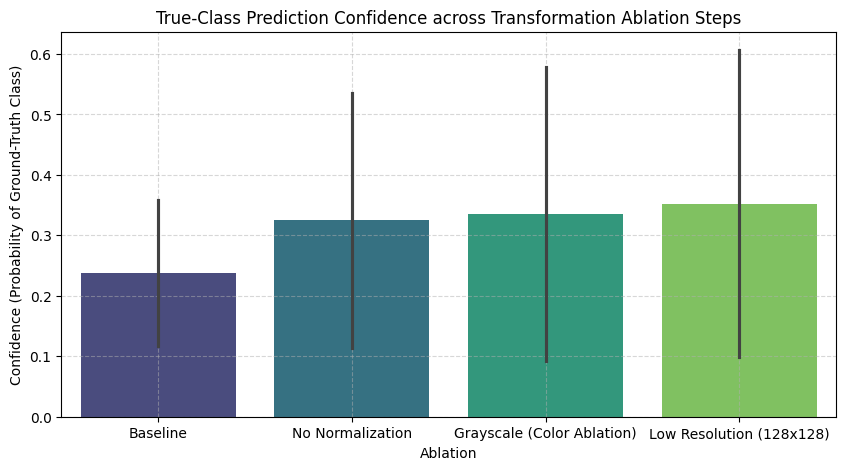

In [59]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torchvision.transforms as T

# 1. Isolate the misclassified image paths and ground truths using the clean ResNet50
clean_model.load_state_dict(torch.load("resnet50_clean_best.pt", map_location=DEVICE))
clean_model.eval()

misclassified_paths = []
misclassified_gts = []

val_dataset_raw = ImageDataset(X_val, y_val, val_transform)
with torch.no_grad():
    for idx in range(len(val_dataset_raw)):
        x, y = val_dataset_raw[idx]
        x = x.unsqueeze(0).to(DEVICE)
        with torch.amp.autocast('cuda', enabled=(DEVICE == "cuda")):
            logits = clean_model(x)
        pred = logits.argmax(1).item()
        if pred != y:
            misclassified_paths.append(X_val[idx])
            misclassified_gts.append(y)

print(f"Extracted {len(misclassified_paths)} baseline misclassified images for ablation.")

# 2. Define Ablation Pipelines
ablation_pipelines = {
    "Baseline": T.Compose([
        T.Resize((224, 224)),
        T.ToTensor(),
        T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    "No Normalization": T.Compose([
        T.Resize((224, 224)),
        T.ToTensor()
    ]),
    "Grayscale (Color Ablation)": T.Compose([
        T.Resize((224, 224)),
        T.Grayscale(num_output_channels=3),
        T.ToTensor(),
        T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    "Low Resolution (128x128)": T.Compose([
        T.Resize((128, 128)),
        T.Resize((224, 224)), # Scale back up for model entry
        T.ToTensor(),
        T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])
}

# 3. Evaluate Ablations
results = []

for path, gt in zip(misclassified_paths, misclassified_gts):
    img_pil = Image.open(path).convert("RGB")
    filename = path.split("/")[-2] + "/" + path.split("/")[-1]

    for config_name, transform_pipeline in ablation_pipelines.items():
        tensor = transform_pipeline(img_pil).unsqueeze(0).to(DEVICE)
        with torch.no_grad():
            with torch.amp.autocast('cuda', enabled=(DEVICE == "cuda")):
                logits = clean_model(tensor)
                probs = torch.softmax(logits, dim=1)[0]
                pred = logits.argmax(1).item()

        is_correct = (pred == gt)
        confidence_correct_class = probs[gt].item()

        results.append({
            "Image": filename,
            "True Class": CLASSES[gt],
            "Ablation": config_name,
            "Predicted": CLASSES[pred],
            "Is Correct": is_correct,
            "Conf (True Class)": confidence_correct_class
        })

df_ablation = pd.DataFrame(results)

# 4. Display Ablation Study Summary Table
summary_pivot = df_ablation.pivot(index="Image", columns="Ablation", values="Conf (True Class)")
print("\n=== Probability of True Class across Ablation Settings ===")
display(summary_pivot)

# 5. Plot average true-class confidence shift across ablations
plt.figure(figsize=(10, 5))
sns.barplot(data=df_ablation, x="Ablation", y="Conf (True Class)", palette="viridis", errorbar="sd")
plt.title("True-Class Prediction Confidence across Transformation Ablation Steps")
plt.ylabel("Confidence (Probability of Ground-Truth Class)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()


### Visualizing Error Attention Maps using Grad-CAM
We will use Grad-CAM on our best clean **ResNet50** model (`resnet50_clean_best.pt`) to inspect the visual attention maps specifically for the misclassified images. This helps diagnose whether the failures are due to background features, physical alterations, or occluded security features.

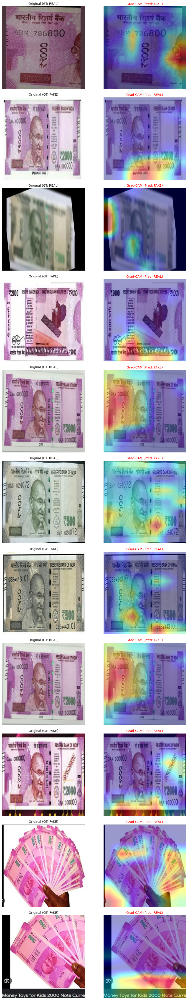

In [67]:
import torch
import numpy as np
import cv2
import matplotlib.pyplot as plt
from PIL import Image

# 1. Load clean ResNet50 model and state dictionary
clean_model.load_state_dict(torch.load("resnet50_clean_best.pt", map_location=DEVICE))
clean_model.eval()

# 2. Extract the misclassified images
misclass_paths = []
misclass_gts = []
misclass_preds = []

with torch.no_grad():
    for idx in range(len(val_dataset_raw)):
        x, y = val_dataset_raw[idx]
        x = x.unsqueeze(0).to(DEVICE)
        with torch.amp.autocast('cuda', enabled=(DEVICE == "cuda")):
            logits = clean_model(x)
        pred = logits.argmax(1).item()
        if pred != y:
            misclass_paths.append(X_val[idx])
            misclass_gts.append(y)
            misclass_preds.append(pred)

# 3. Grad-CAM Setup
target_layer = clean_model.layer4[-1].conv3  # Last conv layer of ResNet50
gradients = []
activations = []

def backward_hook(module, grad_in, grad_out):
    gradients.clear()
    gradients.append(grad_out[0])

def forward_hook(module, inp, out):
    activations.clear()
    activations.append(out)

h1 = target_layer.register_forward_hook(forward_hook)
h2 = target_layer.register_full_backward_hook(backward_hook)

# 4. Generate and Plot Grad-CAM overlay for each misclassified image
num_samples = len(misclass_paths)
if num_samples > 0:
    fig, axes = plt.subplots(num_samples, 2, figsize=(10, 4 * num_samples))
    if num_samples == 1:
        axes = np.expand_dims(axes, axis=0)

    for idx, (path, gt, pred) in enumerate(zip(misclass_paths, misclass_gts, misclass_preds)):
        # Load image
        img_pil = Image.open(path).convert("RGB")
        img_cv = np.array(img_pil)
        img_cv = cv2.cvtColor(img_cv, cv2.COLOR_RGB2BGR)

        # Process image for model entry
        tensor = val_transform(img_pil).unsqueeze(0).to(DEVICE)

        # Forward pass
        clean_model.zero_grad()
        output = clean_model(tensor)
        class_score = output[0, pred]

        # Backward pass
        class_score.backward()

        # Compute CAM
        grads = gradients[0].cpu().detach().numpy()[0]
        acts = activations[0].cpu().detach().numpy()[0]
        weights = np.mean(grads, axis=(1, 2))
        cam = np.zeros(acts.shape[1:], dtype=np.float32)
        for i, w in enumerate(weights):
            cam += w * acts[i, :, :]

        cam = np.maximum(cam, 0)
        if cam.max() > 0:
            cam = cam / cam.max()

        # Resize and Overlay
        cam = cv2.resize(cam, (img_cv.shape[1], img_cv.shape[0]))
        heatmap = np.uint8(255 * cam)
        heatmap_color = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
        overlay = cv2.addWeighted(img_cv, 0.6, heatmap_color, 0.4, 0)

        # Plot
        axes[idx, 0].imshow(cv2.cvtColor(img_cv, cv2.COLOR_BGR2RGB))
        axes[idx, 0].set_title(f"Original (GT: {CLASSES[gt].upper()})", fontsize=10)
        axes[idx, 0].axis("off")

        axes[idx, 1].imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
        axes[idx, 1].set_title(f"Grad-CAM (Pred: {CLASSES[pred].upper()})", fontsize=10, color="red")
        axes[idx, 1].axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No misclassified images found.")

# Remove Hooks
h1.remove()
h2.remove()

### Quantitative Confidence Score Comparison on Misclassified Samples
Now, we evaluate the prediction confidence (probability assigned to the **correct ground-truth class**) across our three clean architectures (**ResNet34**, **ResNet50**, and **ResNet101**) specifically for the 11 baseline misclassified validation images to identify model-specific struggles.

=== True-Class Prediction Confidence (Higher is Better) ===


Model,ResNet101,ResNet34,ResNet50
Image,,,
2000/24.jpg,0.506583,0.762969,0.304153
2000/3.jpg,0.506583,0.762969,0.304153
2000/42.jpg,0.368986,0.273235,0.143501
2000/Screenshot 2025-10-12 105801.png,0.442861,0.425559,0.302653
2000/Screenshot 2025-10-12 110108.png,0.413278,0.412612,0.476640
2000/Screenshot 2025-10-12 110115.png,0.623982,0.738665,0.277994
2000/Screenshot 2025-10-13 143707.png,0.370768,0.222297,0.223581
2000/sssss.jpg,0.225336,0.051257,0.289311
500/39_aug2.jpg,0.335403,0.664317,0.148418


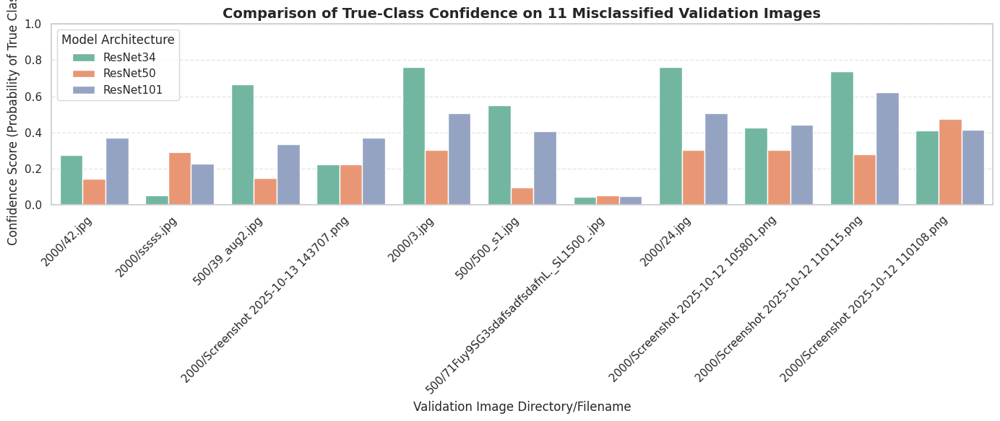

In [68]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# 1. Ensure models are initialized and loaded with clean weights
models_eval = {
    "ResNet34": (clean_model_34, "resnet34_clean_best.pt"),
    "ResNet50": (clean_model, "resnet50_clean_best.pt"),
    "ResNet101": (clean_model_101, "resnet101_clean_best.pt")
}

# 2. Re-extract the 11 misclassified validation images using ResNet50 as our baseline
clean_model.load_state_dict(torch.load("resnet50_clean_best.pt", map_location=DEVICE))
clean_model.eval()

baseline_misclassified_paths = []
baseline_misclassified_gts = []

val_dataset_raw = ImageDataset(X_val, y_val, val_transform)
with torch.no_grad():
    for idx in range(len(val_dataset_raw)):
        x, y = val_dataset_raw[idx]
        x = x.unsqueeze(0).to(DEVICE)
        with torch.amp.autocast('cuda', enabled=(DEVICE == "cuda")):
            logits = clean_model(x)
        pred = logits.argmax(1).item()
        if pred != y:
            baseline_misclassified_paths.append(X_val[idx])
            baseline_misclassified_gts.append(y)

# 3. Gather confidence scores for the correct ground-truth class across all models
comparison_results = []

for path, gt in zip(baseline_misclassified_paths, baseline_misclassified_gts):
    img_pil = Image.open(path).convert("RGB")
    filename = f"{path.split('/')[-2]}/{path.split('/')[-1]}"
    tensor = val_transform(img_pil).unsqueeze(0).to(DEVICE)

    for model_name, (m_obj, w_path) in models_eval.items():
        m_obj.load_state_dict(torch.load(w_path, map_location=DEVICE))
        m_obj.eval()

        with torch.no_grad():
            with torch.amp.autocast('cuda', enabled=(DEVICE == "cuda")):
                logits = m_obj(tensor)
                probs = torch.softmax(logits, dim=1)[0]
                pred_idx = logits.argmax(1).item()

        # Confidence of the true class (closer to 1.0 means the model was closer to being correct)
        conf_true = probs[gt].item()
        predicted_class = CLASSES[pred_idx]

        comparison_results.append({
            "Image": filename,
            "True Class": CLASSES[gt].upper(),
            "Model": model_name,
            "Predicted Class": predicted_class.upper(),
            "True Class Confidence": conf_true
        })

df_conf_compare = pd.DataFrame(comparison_results)

# 4. Display Comparison Table
pivot_conf = df_conf_compare.pivot(index="Image", columns="Model", values="True Class Confidence")
print("=== True-Class Prediction Confidence (Higher is Better) ===")
display(pivot_conf)

# 5. Plot Comparison Chart
plt.figure(figsize=(14, 6))
sns.barplot(data=df_conf_compare, x="Image", y="True Class Confidence", hue="Model", palette="Set2")
plt.title("Comparison of True-Class Confidence on 11 Misclassified Validation Images", fontsize=14, fontweight='bold')
plt.ylabel("Confidence Score (Probability of True Class)")
plt.xlabel("Validation Image Directory/Filename")
plt.xticks(rotation=45, ha='right')
plt.ylim(0, 1.0)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(title="Model Architecture")
plt.tight_layout()
plt.show()


=== Average Confidence on Correct Class (REAL vs FAKE) ===


Model,ResNet101,ResNet34,ResNet50
True Class,,,
FAKE,0.353688,0.315687,0.270246
REAL,0.424537,0.602794,0.199123


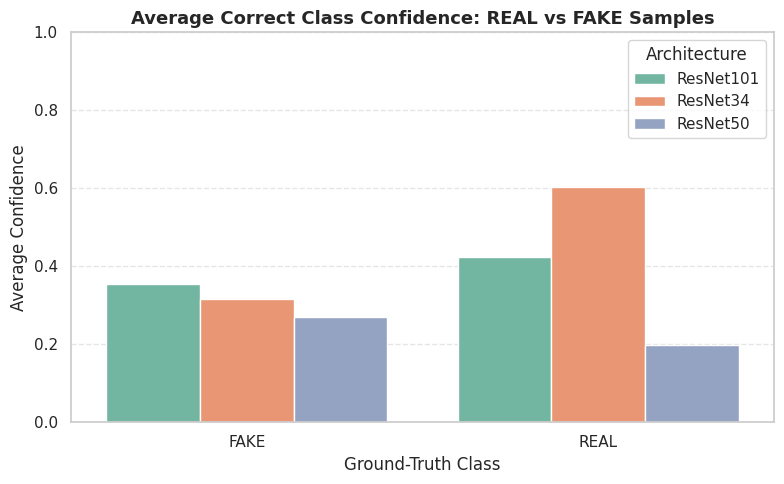

In [69]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate average true-class confidence grouped by Class and Model
avg_conf_df = df_conf_compare.groupby(['True Class', 'Model'])['True Class Confidence'].mean().reset_index()

print("=== Average Confidence on Correct Class (REAL vs FAKE) ===")
display(avg_conf_df.pivot(index='True Class', columns='Model', values='True Class Confidence'))

# Plot the comparison
plt.figure(figsize=(8, 5))
sns.barplot(data=avg_conf_df, x='True Class', y='True Class Confidence', hue='Model', palette='Set2')
plt.title("Average Correct Class Confidence: REAL vs FAKE Samples", fontsize=13, fontweight='bold')
plt.ylabel("Average Confidence")
plt.xlabel("Ground-Truth Class")
plt.ylim(0, 1.0)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(title="Architecture", loc="upper right")
plt.tight_layout()
plt.show()

In [70]:
import numpy as np
import pandas as pd
from scipy import stats

# Extract the confidence scores per model across the same 11 images
# Ensure they are sorted identically by Image name for a proper paired analysis
df_sorted = df_conf_compare.sort_values(by=['Image', 'Model'])
pivot_scores = df_sorted.pivot(index='Image', columns='Model', values='True Class Confidence')

# Extract vectors
r34_scores = pivot_scores['ResNet34'].values
r50_scores = pivot_scores['ResNet50'].values
r101_scores = pivot_scores['ResNet101'].values

# Helper function to compute Cohen's d for paired samples
def cohen_d_paired(x, y):
    diff = x - y
    return np.mean(diff) / np.std(diff, ddof=1)

# Pairs to compare
comparisons = [
    ("ResNet34", "ResNet50", r34_scores, r50_scores),
    ("ResNet101", "ResNet50", r101_scores, r50_scores),
    ("ResNet101", "ResNet34", r101_scores, r34_scores)
]

stats_results = []
for name_a, name_b, scores_a, scores_b in comparisons:
    t_stat, p_val = stats.ttest_rel(scores_a, scores_b)
    d = cohen_d_paired(scores_a, scores_b)
    stats_results.append({
        "Comparison": f"{name_a} vs {name_b}",
        "t-statistic": t_stat,
        "p-value": p_val,
        "Cohen's d": d,
        "Significant (alpha=0.05)": "Yes" if p_val < 0.05 else "No"
    })

df_stats = pd.DataFrame(stats_results)
print("=== Pairwise Paired t-Test and Cohen's d Metrics ===")
display(df_stats)


=== Pairwise Paired t-Test and Cohen's d Metrics ===


,Comparison,t-statistic,p-value,Cohen's d,Significant (alpha=0.05)
0,ResNet34 vs ResNet50,2.570551,0.027864,0.775050,Yes
1,ResNet101 vs ResNet50,3.541815,0.005341,1.067897,Yes
2,ResNet101 vs ResNet34,-1.162879,0.271878,-0.350621,No


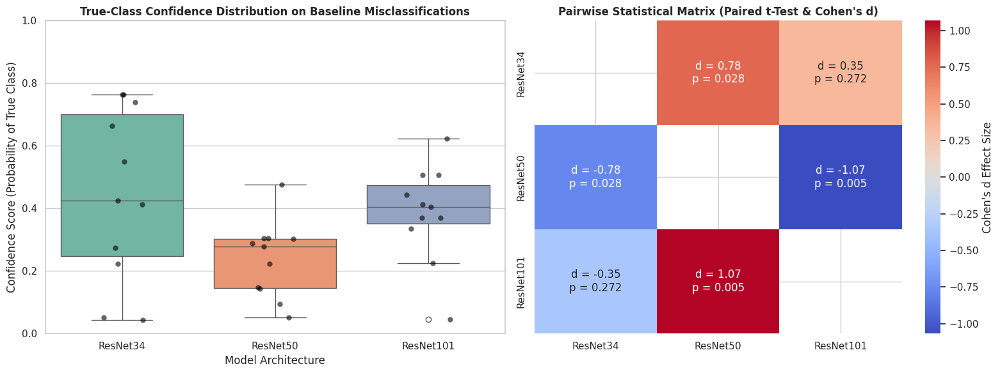

In [71]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Boxplot of prediction confidences on misclassified validation images
sns.boxplot(
    data=df_conf_compare,
    x="Model",
    y="True Class Confidence",
    ax=axes[0],
    palette="Set2",
    hue="Model",
    legend=False
)
sns.stripplot(
    data=df_conf_compare,
    x="Model",
    y="True Class Confidence",
    ax=axes[0],
    color="black",
    alpha=0.6,
    size=6,
    jitter=0.15
)
axes[0].set_title("True-Class Confidence Distribution on Baseline Misclassifications", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Confidence Score (Probability of True Class)")
axes[0].set_xlabel("Model Architecture")
axes[0].set_ylim(0.0, 1.0)

# 2. Pairwise Paired t-Test Heatmap (p-values & Cohen's d)
# Pivot statistical metrics for visualization
matrix_p = np.zeros((3, 3))
matrix_d = np.zeros((3, 3))
labels_models = ["ResNet34", "ResNet50", "ResNet101"]

# Map results to matrices
for idx, row in df_stats.iterrows():
    model_a, model_b = row["Comparison"].split(" vs ")
    i, j = labels_models.index(model_a), labels_models.index(model_b)
    matrix_p[i, j] = row["p-value"]
    matrix_p[j, i] = row["p-value"]
    matrix_d[i, j] = row["Cohen's d"]
    matrix_d[j, i] = -row["Cohen's d"]

# Create a consolidated text representation for annotations
annot_labels = np.empty((3, 3), dtype=object)
for i in range(3):
    for j in range(3):
        if i == j:
            annot_labels[i, j] = "-"
        else:
            annot_labels[i, j] = f"d = {matrix_d[i, j]:.2f}\np = {matrix_p[i, j]:.3f}"

mask = np.eye(3, dtype=bool)
sns.heatmap(
    matrix_d,
    annot=annot_labels,
    fmt="",
    cmap="coolwarm",
    center=0,
    xticklabels=labels_models,
    yticklabels=labels_models,
    ax=axes[1],
    cbar_kws={'label': "Cohen's d Effect Size"},
    mask=mask
)
axes[1].set_title("Pairwise Statistical Matrix (Paired t-Test & Cohen's d)", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()


In [72]:
# Combined Table of Clean Dataset Metrics and Edge-Case Summary Stats
combined_performance = comparison_df.copy()

# Map average edge case true-class confidence stats
edge_avg_conf = df_conf_compare.groupby("Model")["True Class Confidence"].mean().reset_index()
# Align Model Names to match comparison_df Model strings ("Model (Clean)")
edge_avg_conf["Model"] = edge_avg_conf["Model"] + " (Clean)"

combined_metrics = pd.merge(comparison_df, edge_avg_conf, on="Model")
combined_metrics.rename(columns={"True Class Confidence": "Avg Hard-Case True Confidence"}, inplace=True)

print("=== COMPREHENSIVE ARCHITECTURAL METRICS ===")
display(combined_metrics)


=== COMPREHENSIVE ARCHITECTURAL METRICS ===


,Model,Accuracy,F1-Score,AUC-ROC,Avg Hard-Case True Confidence
0,ResNet34 (Clean),0.995164,0.996364,0.999145,0.446190
1,ResNet50 (Clean),0.994089,0.995548,0.999227,0.237918
2,ResNet101 (Clean),0.994089,0.995548,0.998850,0.385892
